**15.071 The AI Edge** · Project 1 · Fall 2026

---

# Retail Demand Analytics: Predicting Walmart Item Sales
## TimesFM 3.0 on All 30,490 Series: Version 3 Baseline, Scenarios V4–V6, and WRMSSE

### Background

In version 1 (V1) of the TimesFM notebook, we used the pretrained time-series foundation model **TimesFM 3.0** zero-shot to forecast the daily unit sales of 6,638 regularly selling Walmart item-store series. We split each series in time: the first 80% of the days (to 2015-04-29) formed the history, and the last 20% (389 days) formed the test period. The best V1 model (with price, SNAP and event covariates, using the mean of the forecast quantiles) reached a test **OSR² of 0.558** on those series. In this notebook every model, V1 included, is run on **all 30,490 series**; V1 reaches an OSR² of 0.551 there.

The V1 results pointed to four improvements, which version 3 (V3) applies one at a time:

1. **Rolling forecasts.** V1 forecast all 389 test days from one date, so most test days were forecast months ahead, and the error grew with the horizon (OSR² 0.625 over the first 4 weeks, 0.558 overall). Here we **re-forecast every 4 weeks**, each time adding the sales of the 4 weeks just completed to the history, as a retailer would do in practice.
2. **Stock-out cleaning.** Long runs of zero sales in a series that normally sells are most likely stock-outs, not a lack of demand. We replace completed stock-outs in the history by the sales level before them.
3. **Richer covariates.** We replace the raw price by the **discount** from the item's usual price, and the single event indicator by a **separate flag for each major event** (Christmas, Thanksgiving, New Year and Labor Day).
4. **A calibrated mean forecast.** V1 used the plain average of the 9 forecast quantiles as the mean forecast, and still underestimated total sales by about 10%. Here we learn the **best weighting of the quantiles** from earlier test windows whose sales are already known.

### The forecasting task: 28 days ahead

Throughout this notebook, every model solves the **same task as the M5 competition: forecast the next 28 days**. On each of 14 forecast dates, one every 28 days, each model uses only the sales known on that date and forecasts the following **1 to 28 days** (25 for the last date). No model in this notebook ever uses sales from inside the 28-day window it is forecasting.

### How this notebook is organized

| Part | Content |
|---|---|
| **Part 1: V3 baseline** | Rolling TimesFM forecasts, stock-out cleaning, covariates and calibrated mean, now also scored with **WRMSSE**, the official M5 accuracy metric |
| **Part 2: Scenarios** | Three changes to V3, each tested on the same 28-day task: **A (V4)** a hybrid TimesFM + LASSO model; **B (V5)** fine-tuning TimesFM's output head; **C (V6)** an ensemble with a recursive gradient-boosted model |
| **Part 3: Comparison** | V3 to V6 side by side on OSR², RMSE, MAE, WAPE and WRMSSE |
| **Part 4: Limits** | What stops the accuracy from improving further |

The data (all 30,490 series), the 80% / 20% time split and the metrics are the same in every part, so all results are directly comparable.

*Run time.* The V1 forecasts (`timesfm3_forecasts_covariates_all30490.npz`), the TimesFM forecasts (folder `timesfm3_v3_forecasts_all30490`), the frozen TimesFM features of Scenario B (`timesfm3_v5_features_all30490`) and the gradient-boosted forecasts of Scenario C (`timesfm3_v6_gbm_all30490`) are saved to disk. Computing them took about 2.5 hours on one NVIDIA L40S GPU of the MIT ORCD Engaging cluster. With these files in place, the whole notebook runs in about 15 minutes on a CPU node.

> **All 30,490 series.** This version runs the V3 baseline and the V4–V6 scenarios on **all 30,490 item-store series** of the M5 data, instead of the 6,638 that sold on more than 50% of days. Nothing else in the method changes. Three adjustments are needed because the slow and newly launched series are now included:
>
> 1. **New products.** 415 series go on sale for the first time after the training period. At a forecast date before their launch, they get an empty history and TimesFM forecasts 0. Their regular price (for the discount covariate) is their first price, and they are never cleaned for stock-outs.
> 2. **V1 reference.** The saved V1 forecasts cover only the 6,638 regular sellers, so the V1 model is recomputed for all series.
> 3. **Caches.** The forecasts and features are saved in separate `*_all30490` folders, so nothing from the 6,638-series run is reused.
>
> 4. **Fine-tuning with normalized weights (Scenario B).** Series whose whole history is zero have a scale of 0. They are left out of the *normalized* loss, which divides by the scale; their forecast does not depend on the head anyway.
>
> The notebook was run on the MIT ORCD Engaging cluster (TimesFM forecasts on an NVIDIA L40S GPU). We also report the **WAPE** next to the other metrics.

# Part 1: The V3 Baseline

We start by locating the data files and importing the Python packages used throughout this notebook. TimesFM 3.0 is installed with `pip install "timesfm[torch]"`.

In [1]:
import os

# DATA_DIR is the folder that holds the three M5 csv files. We look in the
# notebook's own folder first, then in its parent folder. If you have moved the
# notebook or the data, set it by hand instead, for example:
#     DATA_DIR = '/path/to/m5/data'
DATA_FILES = ('sales_train_evaluation.csv', 'calendar.csv', 'sell_prices.csv')
DATA_DIR = None
for candidate in (os.getcwd(), os.path.dirname(os.getcwd())):
    if all(os.path.isfile(os.path.join(candidate, f)) for f in DATA_FILES):
        DATA_DIR = candidate
        break
if DATA_DIR is None:
    raise RuntimeError('Data files not found: set DATA_DIR by hand above.')

print('Data directory:', DATA_DIR)

Data directory: ~/tfm_all30490


In [2]:
import time
import numpy as np
import pandas as pd
import torch
from timesfm3 import TimesFM3Evaluator, ModelConfig
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns

~/envs/tfm/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data Preparation

The steps below are the same as in V1: we load the three M5 files, keep **all 30,490** item-store series (no filter on how often they sell), and build two matrices with one row per series and one column per day: `units` (units sold) and `price` (selling price, missing before the item was first stocked in that store).

In [3]:
sales_wide = pd.read_csv(os.path.join(DATA_DIR, 'sales_train_evaluation.csv'))
calendar   = pd.read_csv(os.path.join(DATA_DIR, 'calendar.csv'))
prices     = pd.read_csv(os.path.join(DATA_DIR, 'sell_prices.csv'))

d_cols = [c for c in sales_wide.columns if c.startswith('d_')]

# All 30,490 item-store series are kept: no filter on the share of days with sales
selling_share = (sales_wide[d_cols] > 0).mean(axis=1)
n_series = len(sales_wide)

print(f"Series kept: {n_series:,} of {len(selling_share):,} (100%)")
print(f"Series that sold on more than 50% of days (the 6,638-series notebook's filter): "
      f"{(selling_share > 0.5).sum():,}")

Series kept: 30,490 of 30,490 (100%)
Series that sold on more than 50% of days (the 6,638-series notebook's filter): 6,638


In [4]:
units = sales_wide[d_cols].to_numpy(dtype=np.float32)

cal = calendar.set_index('d').loc[d_cols]
dates = pd.to_datetime(cal['date']).to_numpy()
day_week = cal['wm_yr_wk'].to_numpy()

weeks = np.unique(day_week)
price_weekly = (prices.pivot(index=['store_id', 'item_id'], columns='wm_yr_wk', values='sell_price')
                      .reindex(index=pd.MultiIndex.from_frame(sales_wide[['store_id', 'item_id']]),
                               columns=weeks))
price = price_weekly.to_numpy(dtype=np.float32)[:, np.searchsorted(weeks, day_week)]
on_sale = ~np.isnan(price)

# First day each item was on sale in its store: the days before are not real zero sales
first_day = on_sale.argmax(axis=1)

print(f"Matrices: {units.shape[0]:,} series x {units.shape[1]:,} days")
print(f"Series first on sale after the training period (no training history): "
      f"{(first_day >= int(0.8 * len(d_cols))).sum():,}")

Matrices: 30,490 series x 1,941 days
Series first on sale after the training period (no training history): 415


## Training and Test Sets, and the Forecast Dates

The split is the same as in V1: the **training set** is the first 80% of the days (`d_1` to `d_1552`, up to 2015-04-29) and the **test set** is the last 20% (`d_1553` to `d_1941`, 389 days). We evaluate on the test days on which the item was on sale.

What changes is **when** the forecasts are made. Instead of one forecast of all 389 days on 2015-04-29, we make **14 forecasts**, one every 28 days:

| Forecast date | History available | Days forecast |
|---|---|---|
| 2015-04-29 (end of training) | up to 2015-04-29 | test days 1–28 |
| 2015-05-27 | up to 2015-05-27 | test days 29–56 |
| … | … | … |
| 2016-04-26 | up to 2016-04-26 | test days 365–389 |

Each forecast uses only sales that are **already known on its forecast date**. The test days that are being predicted are never part of the history. The sales of earlier test windows enter the history once they are in the past, exactly as they would for a store manager re-ordering every four weeks. The task is now to forecast **1 to 28 days ahead**, rather than 1 to 389 days ahead as in V1.

To keep the run time manageable, each forecast uses the **last 1,024 days** (about 2.8 years) of history. This still includes two to three occurrences of every yearly event.

In [5]:
T = len(d_cols)
n_train_days = int(0.8*T)
horizon = T - n_train_days

y_train, y_test = units[:, :n_train_days], units[:, n_train_days:]
train_mask, test_mask = on_sale[:, :n_train_days], on_sale[:, n_train_days:]

WINDOW = 28              # days forecast from each forecast date
CONTEXT_DAYS = 1024      # days of history given to the model

origins = np.arange(n_train_days, T, WINDOW)
window_of_day = np.arange(horizon) // WINDOW          # window index of each test day
day_ahead = np.arange(horizon) % WINDOW + 1           # 1 to 28 days ahead

fmt = lambda d: pd.Timestamp(d).strftime('%Y-%m-%d')
print(f"Training days: {n_train_days:,} | Test days: {horizon:,} | "
      f"Test observations: {test_mask.sum():,}")
print(f"Forecast dates: {len(origins)} (last history day {fmt(dates[origins[0]-1])} "
      f"to {fmt(dates[origins[-1]-1])})")

Training days: 1,552 | Test days: 389 | Test observations: 11,830,233
Forecast dates: 14 (last history day 2015-04-29 to 2016-04-27)


### Performance Metrics

We use the same measures as in V1: **OSR²** relative to the training-set average, **RMSE** and **MAE**, all on the test observations. We add the **WRMSSE**, defined below, and the **WAPE** (weighted absolute percentage error), $\sum |y - \hat y| / \sum y$: the total absolute error as a share of total units sold. WAPE reads as "we miss by X% of volume" and, unlike MAPE, is well defined on days with zero sales. Lower is better for RMSE, MAE, WAPE and WRMSSE.

In [6]:
def osr2(pred, y_test, y_train_mean):
    return 1 - np.sum((pred - y_test)**2) / np.sum((y_train_mean - y_test)**2)

def rmse(pred, y):
    return np.sqrt(np.mean((pred - y)**2))

def mae(pred, y):
    return np.mean(np.abs(pred - y))

def wape(pred, y):
    return np.sum(np.abs(pred - y)) / np.sum(y)

y_train_mean = y_train[train_mask].mean()
y_test_obs = y_test[test_mask]

# wrmsse() is defined in the next cell; evaluate() is first called after it
def evaluate(name, pred):
    p = pred[test_mask]
    return {'Model': name,
            'OSR²': osr2(p, y_test_obs, y_train_mean),
            'RMSE': rmse(p, y_test_obs),
            'MAE': mae(p, y_test_obs),
            'WAPE': wape(p, y_test_obs),
            'WRMSSE': wrmsse(pred)}

print(f"Training mean (OSR² benchmark): {y_train_mean:.3f} units/day")

Training mean (OSR² benchmark): 1.468 units/day


### WRMSSE, the M5 Accuracy Metric

OSR², RMSE, MAE and WAPE treat every series-day the same, so they are dominated by the best-sellers. The M5 competition ranked forecasts by the **Weighted Root Mean Squared Scaled Error (WRMSSE)**, which differs in three ways.

**1. It scores 12 levels of aggregation.** Item-store forecasts are added up to the store total, the state total, the department total, and so on, and each level is scored. A forecast that is unbiased item by item but wrong for the store as a whole is penalized.

| Level | Series | Level | Series |
|---|---|---|---|
| 1. Total | 1 | 7. State × department | 21 |
| 2. State | 3 | 8. Store × category | 30 |
| 3. Store | 10 | 9. Store × department | 70 |
| 4. Category | 3 | 10. Item | 3,049 |
| 5. Department | 7 | 11. Item × state | 9,147 |
| 6. State × category | 9 | 12. Item × store | 30,490 |

**2. Each series' error is scaled by how hard it is to forecast.** For series $i$, the RMSSE divides the squared forecast error by the squared error of the naive "same as yesterday" forecast in its history:

$$\text{RMSSE}_i = \sqrt{\frac{\frac{1}{h}\sum_{t=n+1}^{n+h} (y_{i,t} - \hat y_{i,t})^2}{\frac{1}{n - s_i}\sum_{t=s_i+1}^{n} (y_{i,t} - y_{i,t-1})^2}},$$

where $n$ is the last history day, $h = 28$ the horizon, and $s_i$ the first day with sales. An RMSSE below 1 means the forecast beats the one-step naive error of the history.

**3. Series are weighted by dollar sales.** Each series' weight is its share of **dollar sales over the last 28 days** before the forecast date within its level, and each of the 12 levels gets 1/12 of the total weight:

$$\text{WRMSSE} = \sum_{\text{levels}} \frac{1}{12} \sum_{i \in \text{level}} w_i \cdot \text{RMSSE}_i .$$

**Lower is better.** The M5 winner scored 0.520 and the best statistical benchmark (exponential smoothing, bottom-up) about 0.671.

**Our adaptation.** The competition scored one 28-day window. We have 14 rolling 28-day windows, so we compute the WRMSSE of **each window**, with the scale and the weights taken from the history known on its forecast date, and report the **average over the 14 windows**. The hierarchy is built from **all 30,490 series**, as in the competition (42,840 series over the 12 levels). Our WRMSSE is still **not directly comparable with the M5 leaderboard**, because we average 14 windows spread over a year (including Christmas and Thanksgiving) instead of scoring one window in May–June 2016, but it is comparable across all the models in this notebook.

In [7]:
import scipy.sparse as sp

LEVELS = [('Total', []), ('State', ['state_id']), ('Store', ['store_id']), ('Category', ['cat_id']),
          ('Department', ['dept_id']), ('State x category', ['state_id', 'cat_id']),
          ('State x department', ['state_id', 'dept_id']), ('Store x category', ['store_id', 'cat_id']),
          ('Store x department', ['store_id', 'dept_id']), ('Item', ['item_id']),
          ('Item x state', ['item_id', 'state_id']), ('Item x store', ['item_id', 'store_id'])]

# Aggregation matrix: one row per aggregated series, one column per item-store series
blocks, level_of_row = [], []
for j, (name, keys) in enumerate(LEVELS):
    if keys:
        codes, groups = pd.factorize(sales_wide[keys].astype(str).agg('|'.join, axis=1))
        n_groups = len(groups)
    else:
        codes, n_groups = np.zeros(n_series, dtype=int), 1
    blocks.append(sp.csr_matrix((np.ones(n_series, dtype=np.float32), (codes, np.arange(n_series))),
                                shape=(n_groups, n_series)))
    level_of_row.append(np.full(n_groups, j))
AGG = sp.vstack(blocks).tocsr()
level_of_row = np.concatenate(level_of_row)

# Actual units and dollar sales of every aggregated series (days not on sale count as 0)
units_on_sale = np.where(on_sale, units, 0).astype(np.float32)
agg_units = np.asarray(AGG @ units_on_sale, dtype=np.float64)
agg_dollars = np.asarray(AGG @ np.where(on_sale, units * np.nan_to_num(price), 0).astype(np.float32),
                         dtype=np.float64)
agg_test = agg_units[:, n_train_days:]

# Scale: mean squared one-day change from the first day with sales up to the forecast date,
# computed with cumulative sums so that it can be read for any forecast date
sq_diff_cum = np.hstack([np.zeros((AGG.shape[0], 1)), np.cumsum(np.diff(agg_units, axis=1)**2, axis=1)])
first_sale = (agg_units > 0).argmax(axis=1)

wrmsse_scale, wrmsse_weight = [], []
for origin in origins:
    scale = (sq_diff_cum[:, origin - 1] - sq_diff_cum[np.arange(AGG.shape[0]), first_sale]) \
            / np.maximum(origin - 1 - first_sale, 1)
    wrmsse_scale.append(np.maximum(scale, 1e-8))
    dollars = agg_dollars[:, origin - 28:origin].sum(axis=1)
    weight = np.zeros_like(dollars)
    for j in range(len(LEVELS)):
        in_level = level_of_row == j
        weight[in_level] = dollars[in_level] / dollars[in_level].sum() / len(LEVELS)
    wrmsse_weight.append(weight)
del sq_diff_cum, agg_dollars, agg_units          # free memory: only the test-period actuals are needed

def wrmsse(pred, by_level=False):
    # Average over the 14 forecast windows of the M5 WRMSSE of each 28-day window
    agg_pred = np.asarray(AGG @ np.where(test_mask, pred, 0).astype(np.float32), dtype=np.float64)
    per_window, per_level = [], []
    for k in range(len(origins)):
        cols = window_of_day == k
        rmsse = np.sqrt(((agg_test[:, cols] - agg_pred[:, cols])**2).mean(axis=1) / wrmsse_scale[k])
        contrib = wrmsse_weight[k] * rmsse
        per_window.append(contrib.sum())
        per_level.append([contrib[level_of_row == j].sum() * len(LEVELS) for j in range(len(LEVELS))])
    if by_level:
        return pd.Series(np.mean(per_level, axis=0), index=[name for name, _ in LEVELS])
    return float(np.mean(per_window))

print(f"Aggregated series: {AGG.shape[0]:,} over {len(LEVELS)} levels")
print(pd.Series(np.bincount(level_of_row), index=[name for name, _ in LEVELS]).to_string())

Aggregated series: 42,840 over 12 levels
Total                     1
State                     3
Store                    10
Category                  3
Department                7
State x category          9
State x department       21
Store x category         30
Store x department       70
Item                   3049
Item x state           9147
Item x store          30490


## Loading TimesFM 3.0

As in V1, we load the pretrained checkpoint `google/timesfm-3.0-pytorch` and run it on a GPU when one is available. We keep `use_symmetric_averaging=False`, which halves the run time.

*License note:* the TimesFM 3.0 pretrained weights are released under a **non-commercial** license. Using them for coursework is fine; using them in a production system is not.

In [8]:
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'

forecaster = TimesFM3Evaluator(ModelConfig(
    checkpoint_path='google/timesfm-3.0-pytorch',
    per_core_batch_size=128 if device == 'cuda' else 32,
    device=device,
))
print(f"TimesFM 3.0 loaded on '{device}'")

~/envs/tfm/lib/python3.13/site-packages/torch/cuda/__init__.py:241: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12040). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


TimesFM 3.0 loaded on 'cpu'


## Reference Points

We compare V3 with three reference points:

- **V1 TimesFM (with covariates, mean)**: the best V1 model, one forecast of all 389 days. Its forecasts are read from the file saved by the V1 notebook.
- **Last 28 days (rolling)**: on each forecast date, predict each series' average over the previous 28 days. This is the rolling version of the strongest simple benchmark, and the same information as the `roll28` feature of the regression notebooks, refreshed every 4 weeks rather than every day.
- **Seasonal naive (rolling)**: on each forecast date, predict each series' average of the last 4 weeks on the same weekday.

A model that re-forecasts every 4 weeks must beat these rolling benchmarks, which use the same fresh information, to show that it adds value.

In [9]:
results = [evaluate('Training mean', np.full_like(y_test, y_train_mean))]

# V1 (with covariates): one forecast of all 389 test days from the whole training history,
# with price, SNAP and an any-event indicator as covariates. The saved V1 forecasts cover only
# the 6,638 regular sellers, so V1 is recomputed here for all 30,490 series (cached on disk).
V1_FILE = os.path.join(os.getcwd(), 'timesfm3_forecasts_covariates_all30490.npz')
if os.path.isfile(V1_FILE):
    v1 = np.load(V1_FILE)
else:
    v1_price = pd.DataFrame(price).ffill(axis=1).bfill(axis=1).to_numpy(dtype=np.float32)
    v1_snap = {s: cal[f'snap_{s}'].to_numpy(dtype=np.float32) for s in ('CA', 'TX', 'WI')}
    v1_event = cal['event_name_1'].notna().to_numpy(dtype=np.float32)
    v1_state = sales_wide['state_id'].to_numpy()
    v1_start = np.minimum(first_day, n_train_days)       # series launched in the test period: empty history
    v1_point, v1_q = [], []
    t0 = time.time()
    for start in range(0, n_series, 2048):
        idx = range(start, min(start + 2048, n_series))
        ctx = [y_train[i, v1_start[i]:] for i in idx]
        cov = [np.stack([v1_price[i, v1_start[i]:], v1_snap[v1_state[i]][v1_start[i]:], v1_event[v1_start[i]:]])
               for i in idx]
        for out in forecaster.predict_batch(ctx, horizon=horizon, past_future_covariates=cov,
                                            return_quantiles=True, use_symmetric_averaging=False,
                                            make_positive=True):
            v1_point.append(np.asarray(out.forecast).reshape(-1))
            v1_q.append(np.asarray(out.quantiles).reshape(horizon, -1))
        print(f"  V1: {idx.stop:,} / {n_series:,} series | {time.time() - t0:.0f} s")
    np.savez_compressed(V1_FILE, point=np.stack(v1_point), quantiles=np.stack(v1_q))
    v1 = np.load(V1_FILE)
v1_mean = v1['quantiles'].mean(axis=2)
results.append(evaluate('V1 TimesFM (with covariates, mean)', v1_mean))

roll_last28 = np.zeros_like(y_test)
roll_snaive = np.zeros_like(y_test)
for origin in origins:
    h = min(WINDOW, T - origin)
    cols = slice(origin - n_train_days, origin - n_train_days + h)
    recent = units[:, origin - WINDOW:origin]
    roll_last28[:, cols] = recent.mean(axis=1, keepdims=True)
    # Column j of `same_weekday` has the weekday of day origin - 28 + j, which is also the
    # weekday of day origin + j (28 is a multiple of 7)
    same_weekday = recent.reshape(n_series, 4, 7).mean(axis=1)
    roll_snaive[:, cols] = np.tile(same_weekday, 4)[:, :h]

results.append(evaluate('Last 28 days (rolling)', roll_last28))
results.append(evaluate('Seasonal naive (rolling)', roll_snaive))
display(pd.DataFrame(results).round(4))

,Model,OSR²,RMSE,MAE,WAPE,WRMSSE
0,Training mean,0.0000,3.6304,1.7461,1.3339,2.4512
1,"V1 TimesFM (with covariates, mean)",0.5509,2.4329,1.0937,0.8355,0.9569
2,Last 28 days (rolling),0.5776,2.3595,1.0204,0.7795,1.0729
3,Seasonal naive (rolling),0.5431,2.4538,1.0583,0.8085,0.8152


### The Rolling Forecast Loop

The function below makes the 14 forecasts for one model variant. `make_inputs(origin, h)` returns the histories (and, if any, the covariates) known on the forecast date `origin`; the function forecasts the next `h` days and places the results in the right test columns.

Forecasting all series with covariates takes about 15 to 20 minutes per forecast date on a laptop GPU, so each forecast date is **saved to its own file** in the folder `timesfm3_v3_forecasts`. If the notebook is interrupted, running it again picks up where it stopped. Delete the folder to recompute everything.

In [10]:
CACHE_DIR = os.path.join(os.getcwd(), 'timesfm3_v3_forecasts_all30490')
os.makedirs(CACHE_DIR, exist_ok=True)

def context_start(i, origin):
    # min(..., origin): a series first on sale after the forecast date gets an empty history,
    # for which TimesFM forecasts 0
    return min(max(first_day[i], origin - CONTEXT_DAYS), origin)

def rolling_forecast(variant, make_inputs):
    point = np.zeros((n_series, horizon), dtype=np.float32)
    quantiles = np.zeros((n_series, horizon, 9), dtype=np.float32)
    t0 = time.time()
    for k, origin in enumerate(origins):
        h = min(WINDOW, T - origin)
        path = os.path.join(CACHE_DIR, f'{variant}_origin{k:02d}.npz')
        if os.path.isfile(path):
            saved = np.load(path)
            p, q = saved['point'], saved['quantiles']
        else:
            contexts, covariates = make_inputs(origin, h)
            p, q = [], []
            for out in forecaster.predict_batch(contexts, horizon=h, past_future_covariates=covariates,
                                                return_quantiles=True, use_symmetric_averaging=False,
                                                make_positive=True):
                p.append(np.asarray(out.forecast).reshape(-1))
                q.append(np.asarray(out.quantiles).reshape(h, -1))
            p, q = np.stack(p), np.stack(q)
            np.savez_compressed(path, point=p, quantiles=q)
            print(f"  {variant}: forecast date {k + 1}/{len(origins)} done | {time.time() - t0:.0f} s")
        cols = slice(origin - n_train_days, origin - n_train_days + h)
        point[:, cols], quantiles[:, cols] = p, q
    print(f"{variant}: all {len(origins)} forecast dates ready")
    return point, quantiles

## Step 1: Rolling Forecasts

We first change only **when** the forecasts are made. The model is the univariate V1 model (past sales only, no covariates, no cleaning), now re-run every 4 weeks on the latest 1,024 days of history.

In [11]:
def raw_inputs(origin, h):
    return [units[i, context_start(i, origin):origin] for i in range(n_series)], None

pred_s1, q_s1 = rolling_forecast('step1_rolling', raw_inputs)
results.append(evaluate('Step 1: rolling (median)', pred_s1))
display(pd.DataFrame(results).round(4))

step1_rolling: all 14 forecast dates ready


,Model,OSR²,RMSE,MAE,WAPE,WRMSSE
0,Training mean,0.0000,3.6304,1.7461,1.3339,2.4512
1,"V1 TimesFM (with covariates, mean)",0.5509,2.4329,1.0937,0.8355,0.9569
2,Last 28 days (rolling),0.5776,2.3595,1.0204,0.7795,1.0729
3,Seasonal naive (rolling),0.5431,2.4538,1.0583,0.8085,0.8152
4,Step 1: rolling (median),0.6095,2.2688,0.8988,0.6867,1.6125


## Step 2: Cleaning Stock-Outs from the History

For an item that usually sells, a long run of days with **zero sales** is unlikely to happen by chance: most such runs are **stock-outs**, when the item was listed but not on the shelf. In the history, these runs make the item look less popular than it is and distort the level and the uncertainty the model reads.

**Detecting stock-outs.** For each series we measure its share of zero-sale days in the training period, $p_0$. If days were independent, a run of $L$ zero days in a row would have probability $p_0^L$. We flag a run as a stock-out when this probability is below 0.1%, i.e. when $L \geq \log(0.001)/\log(p_0)$, and in any case when it lasts at least 7 days. A series that sells nothing on 20% of days needs a run of 5 days, raised to the 7-day minimum; one that sells nothing on 45% of days needs a run of 9 days; one that sells nothing on 80% of days, typical of the slow sellers now included, needs 31 days. Series with no on-sale day in the training period are never cleaned.

**Cleaning them.** A stock-out that has **ended** before the forecast date is replaced by the average sales of the 28 days just before it (or just after it, at the very start of the history). A stock-out that is **still going on** on the forecast date is kept: it is a real signal that the next days may also have no sales.

The test days are not changed: we still evaluate the forecasts against the actual recorded sales.

Minimum stock-out length: median 16 days | max 6905 days
Series with at least one cleaned stock-out: 24,121 of 30,490
History days cleaned: 4,286,058 of 26,408,123 (16.23%)


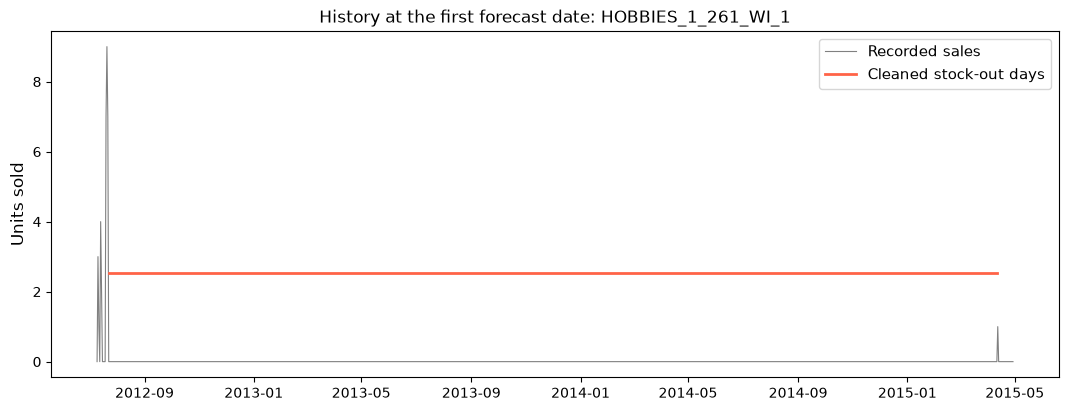

In [12]:
MIN_STOCKOUT_DAYS = 7

# Share of zero-sale days among on-sale training days. Series with no on-sale training day
# get 0.999, i.e. a minimum stock-out length of several thousand days: they are never cleaned.
n_on_sale_train = train_mask.sum(axis=1)
p0 = np.where(n_on_sale_train > 0,
              ((y_train == 0) & train_mask).sum(axis=1) / np.maximum(n_on_sale_train, 1), 0.999)
p0 = np.clip(p0, 1e-6, 0.999)
min_run = np.maximum(MIN_STOCKOUT_DAYS, np.ceil(np.log(0.001) / np.log(p0))).astype(int)

def zero_runs(x, min_len):
    # (start, end) of each run of at least min_len zeros, with end exclusive
    z = np.concatenate([[0], (x == 0).astype(np.int8), [0]])
    edges = np.diff(z)
    starts, ends = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)
    keep = ends - starts >= min_len
    return starts[keep], ends[keep]

def clean_stockouts(x, min_len):
    x = x.copy()
    for s, e in zip(*zero_runs(x, min_len)):
        if e < len(x):                                   # completed stock-outs only
            before = x[max(0, s - 28):s]
            x[s:e] = before.mean() if len(before) else x[e:e + 28].mean()
    return x

def clean_inputs(origin, h):
    return [clean_stockouts(units[i, context_start(i, origin):origin], min_run[i])
            for i in range(n_series)], None

# How much of the history is affected at the first forecast date?
raw_ctx, _ = raw_inputs(origins[0], WINDOW)
clean_ctx, _ = clean_inputs(origins[0], WINDOW)
changed = [np.sum(c != r) for c, r in zip(clean_ctx, raw_ctx)]
print(f"Minimum stock-out length: median {np.median(min_run):.0f} days | max {min_run.max()} days")
print(f"Series with at least one cleaned stock-out: {np.sum(np.array(changed) > 0):,} of {n_series:,}")
print(f"History days cleaned: {np.sum(changed):,} of {sum(len(r) for r in raw_ctx):,} "
      f"({np.sum(changed) / sum(len(r) for r in raw_ctx):.2%})")

# Example: the series with the most cleaned days
i = int(np.argmax(changed))
ctx_dates = dates[context_start(i, origins[0]):origins[0]]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(ctx_dates, raw_ctx[i], color='grey', linewidth=0.8, label='Recorded sales')
ax.plot(ctx_dates, np.where(clean_ctx[i] != raw_ctx[i], clean_ctx[i], np.nan), color='tomato',
        linewidth=2, label='Cleaned stock-out days')
ax.set_title(f"History at the first forecast date: {sales_wide.loc[i, 'id'].replace('_evaluation', '')}",
             fontsize=12)
ax.set_ylabel('Units sold', fontsize=12)
ax.legend(fontsize=11)
plt.show()

In [13]:
pred_s2, q_s2 = rolling_forecast('step2_stockouts', clean_inputs)
results.append(evaluate('Step 2: + stock-out cleaning (median)', pred_s2))
display(pd.DataFrame(results).round(4))

step2_stockouts: all 14 forecast dates ready


,Model,OSR²,RMSE,MAE,WAPE,WRMSSE
0,Training mean,0.0000,3.6304,1.7461,1.3339,2.4512
1,"V1 TimesFM (with covariates, mean)",0.5509,2.4329,1.0937,0.8355,0.9569
2,Last 28 days (rolling),0.5776,2.3595,1.0204,0.7795,1.0729
3,Seasonal naive (rolling),0.5431,2.4538,1.0583,0.8085,0.8152
4,Step 1: rolling (median),0.6095,2.2688,0.8988,0.6867,1.6125
5,Step 2: + stock-out cleaning (median),0.6189,2.2410,0.9000,0.6875,1.5024


## Step 3: Discount and Major-Event Covariates

In V1 the covariates were the raw price, the SNAP days and a single indicator for all events. We make two changes.

**Price as a discount.** The raw price mostly tells the model which item it is looking at, which the sales history already shows. What changes demand is a price that is **lower than usual**. We define each item-store's *regular price* as its median price over the training period, and give the model

$$\text{discount}_t = 1 - \frac{\text{price}_t}{\text{regular price}},$$

so that 0.2 means 20% off and a negative value means a price above the usual one. As in V1, we assume that planned prices are known over the next 28 days.

**A separate flag for each major event.** The 30 events in the calendar have very different effects: Christmas closes the stores, while many religious and sporting events have no visible effect. Lumping them together blurs the signal. We measure each event's effect on the training data, as the change in total sales on the event day compared with the same weekday in the 4 weeks before and after, and give a separate 0/1 flag to every event that changes total sales by **15% or more**.

**SNAP days** of the store's state are kept as in V1. Each series therefore receives 6 covariate channels: the discount, SNAP, and 4 event flags.

In [14]:
EVENT_EFFECT_MIN = 0.15

# Effect of each event on total sales, measured on the training days only
total_train = y_train.sum(axis=0)
event_1 = cal['event_name_1'].to_numpy()[:n_train_days]
effects = []
for t in np.flatnonzero(pd.notna(event_1)):
    same_weekday = [t + 7*k for k in (-4, -3, -2, -1, 1, 2, 3, 4)
                    if 0 <= t + 7*k < n_train_days and pd.isna(event_1[t + 7*k])]
    effects.append((event_1[t], total_train[t] / total_train[same_weekday].mean() - 1))
effects = pd.DataFrame(effects, columns=['Event', 'Effect']).groupby('Event')['Effect'].mean().sort_values()

major_events = effects[effects.abs() >= EVENT_EFFECT_MIN].index.tolist()
print(f"Major events (effect on total sales of {EVENT_EFFECT_MIN:.0%} or more): {major_events}")
display(pd.concat([effects.head(6), effects.tail(4)]).to_frame('Effect on total sales')
        .style.format('{:+.1%}'))

Major events (effect on total sales of 15% or more): ['Christmas', 'Thanksgiving', 'NewYear', 'LaborDay']


,Effect on total sales
Event,
Christmas,-99.9%
Thanksgiving,-29.4%
NewYear,-21.3%
Mother's day,-14.2%
Easter,-11.8%
Halloween,-11.3%
LentStart,+4.2%
ColumbusDay,+6.9%
VeteransDay,+9.1%


In [15]:
# Discount from the regular (median training) price; days without a price use the latest price
price_filled = pd.DataFrame(price).ffill(axis=1).bfill(axis=1).to_numpy(dtype=np.float32)
regular_price = np.nanmedian(np.where(train_mask, price[:, :n_train_days], np.nan), axis=1)
# Series first on sale after the training period: their first price is the regular price
regular_price = np.where(np.isnan(regular_price), price[np.arange(n_series), first_day], regular_price)
discount = (1 - price_filled / regular_price[:, None]).astype(np.float32)

snap_by_state = {s: cal[f'snap_{s}'].to_numpy(dtype=np.float32) for s in ('CA', 'TX', 'WI')}
state = sales_wide['state_id'].to_numpy()

event_flags = np.stack([((cal['event_name_1'] == e) | (cal['event_name_2'] == e)).to_numpy(dtype=np.float32)
                        for e in major_events])

print(f"Share of test series-days with a discount of 5% or more: "
      f"{np.mean(discount[:, n_train_days:][test_mask] >= 0.05):.1%}")
print(f"Event flags: {event_flags.shape[0]} channels, {int(event_flags.sum())} flagged days in total")

def covariate_inputs(origin, h):
    contexts, _ = clean_inputs(origin, h)
    covariates = []
    for i in range(n_series):
        s, e = context_start(i, origin), origin + h
        covariates.append(np.vstack([discount[i, s:e], snap_by_state[state[i]][s:e], event_flags[:, s:e]]))
    return contexts, covariates

pred_s3, q_s3 = rolling_forecast('step3_covariates', covariate_inputs)
results.append(evaluate('Step 3: + discount, SNAP, major events (median)', pred_s3))
display(pd.DataFrame(results).round(4))

~/envs/tfm/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,


Share of test series-days with a discount of 5% or more: 7.6%
Event flags: 4 channels, 20 flagged days in total


step3_covariates: all 14 forecast dates ready


,Model,OSR²,RMSE,MAE,WAPE,WRMSSE
0,Training mean,0.0000,3.6304,1.7461,1.3339,2.4512
1,"V1 TimesFM (with covariates, mean)",0.5509,2.4329,1.0937,0.8355,0.9569
2,Last 28 days (rolling),0.5776,2.3595,1.0204,0.7795,1.0729
3,Seasonal naive (rolling),0.5431,2.4538,1.0583,0.8085,0.8152
4,Step 1: rolling (median),0.6095,2.2688,0.8988,0.6867,1.6125
5,Step 2: + stock-out cleaning (median),0.6189,2.2410,0.9000,0.6875,1.5024
6,"Step 3: + discount, SNAP, major events (median)",0.6264,2.2190,0.8962,0.6846,1.4922


## Step 4: A Calibrated Mean Forecast

TimesFM's point forecast is the **median**, but OSR² and RMSE reward the **mean**, and daily sales are right-skewed. In V1, the plain average of the 9 quantiles (10%, 20%, …, 90%) improved OSR², but still fell short of the mean: the 9 deciles ignore the long right tail above the 90% quantile.

Here we **learn** how to combine the quantiles into a mean forecast. We regress the actual sales on the 9 quantile forecasts, with non-negative weights and an intercept. The weights must be learned on sales that are already known when the forecast is made. So for the forecasts of window $k$, we fit the weights on windows $1, \dots, k-1$ of the test period, whose forecasts and actual sales are both known by then. Window 1 has no earlier window, so it uses the plain average of the quantiles.

We apply this to the three steps, so that each step's gain can be measured with the best point forecast.

In [16]:
def calibrated_mean(q):
    out = q.mean(axis=2)                     # window 1: plain average of the quantiles
    for k in range(1, len(origins)):
        fit = test_mask & (window_of_day < k)[None, :]
        cols = window_of_day == k
        reg = LinearRegression(positive=True).fit(q[fit], y_test[fit])
        out[:, cols] = np.clip(reg.predict(q[:, cols].reshape(-1, q.shape[2])).reshape(n_series, -1), 0, None)
    return out, reg

steps = [('Step 1: rolling', q_s1), ('Step 2: + stock-out cleaning', q_s2),
         ('Step 3: + discount, SNAP, major events', q_s3)]
calibrated = {}
for name, q in steps:
    results.append(evaluate(f'{name} (quantile average)', q.mean(axis=2)))
    calibrated[name], last_reg = calibrated_mean(q)
    results.append(evaluate(f'{name} (calibrated mean)', calibrated[name]))

pred_best = calibrated['Step 3: + discount, SNAP, major events']
print("Weights of the 9 quantiles in the last window, Step 3 model:")
print(pd.Series(last_reg.coef_, index=[f'q{10*j}' for j in range(1, 10)]).round(3).to_string(),
      f"\nintercept {last_reg.intercept_:.3f}")

Weights of the 9 quantiles in the last window, Step 3 model:
q10    0.187
q20    0.000
q30    0.214
q40    0.149
q50    0.042
q60    0.000
q70    0.090
q80    0.105
q90    0.192 
intercept 0.039


## Results

### Model Comparison

All models are scored on the same test observations (actual daily sales, on-sale days of the last 389 days).

In [17]:
results_df = pd.DataFrame(results).set_index('Model')
display(results_df.round(4).style
        .highlight_max(subset=['OSR²'], color='lightgreen')
        .highlight_min(subset=['RMSE', 'MAE', 'WAPE', 'WRMSSE'], color='lightgreen')
        .format('{:.4f}'))

# The gain of each step, by type of point forecast
step_table = pd.DataFrame({
    point: [results_df.loc[f'{name} ({point})', 'OSR²'] for name, _ in steps]
    for point in ['median', 'quantile average', 'calibrated mean']
}, index=[name for name, _ in steps])
step_table.columns = [f'OSR², {c}' for c in step_table.columns]
display(step_table.round(4))

,OSR²,RMSE,MAE,WAPE,WRMSSE
Model,,,,,
Training mean,0.0000,3.6304,1.7461,1.3339,2.4512
"V1 TimesFM (with covariates, mean)",0.5509,2.4329,1.0937,0.8355,0.9569
Last 28 days (rolling),0.5776,2.3595,1.0204,0.7795,1.0729
Seasonal naive (rolling),0.5431,2.4538,1.0583,0.8085,0.8152
Step 1: rolling (median),0.6095,2.2688,0.8988,0.6867,1.6125
Step 2: + stock-out cleaning (median),0.6189,2.2410,0.9000,0.6875,1.5024
"Step 3: + discount, SNAP, major events (median)",0.6264,2.2190,0.8962,0.6846,1.4922
Step 1: rolling (quantile average),0.6191,2.2405,0.9660,0.7380,0.8740
Step 1: rolling (calibrated mean),0.6212,2.2343,1.0051,0.7678,0.8016


,"OSR², median","OSR², quantile average","OSR², calibrated mean"
Step 1: rolling,0.6095,0.6191,0.6212
Step 2: + stock-out cleaning,0.6189,0.6310,0.6301
"Step 3: + discount, SNAP, major events",0.6264,0.6410,0.6415


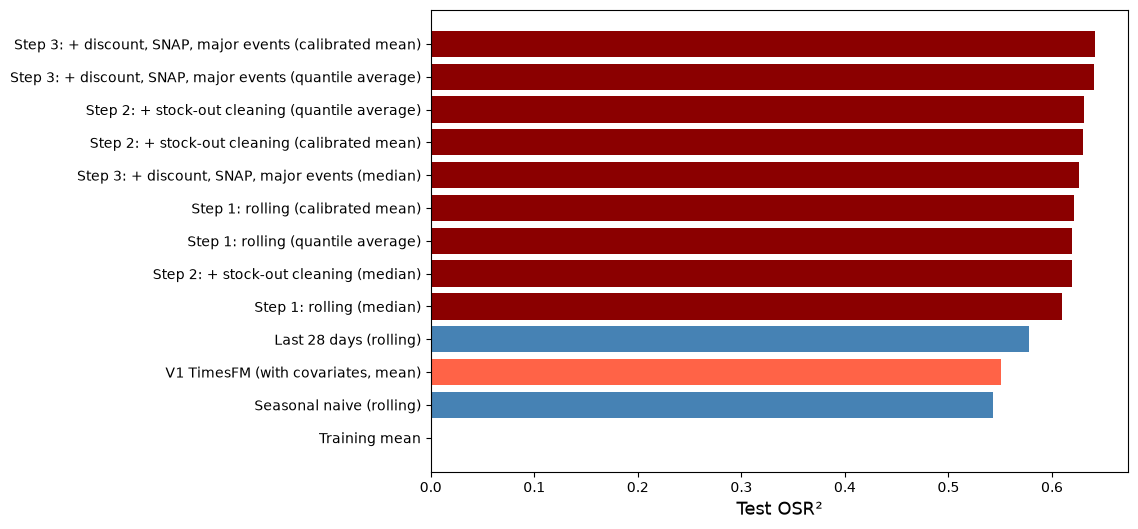

In [18]:
plot_df = results_df.reset_index().sort_values('OSR²')
colors = ['darkred' if m.startswith('Step') else 'tomato' if m.startswith('V1') else 'steelblue'
          for m in plot_df['Model']]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_df['Model'], plot_df['OSR²'], color=colors)
ax.set_xlabel('Test OSR²', fontsize=13)
plt.show()

### Accuracy by Days Ahead

Each forecast covers 1 to 28 days ahead. The plot shows the RMSE by number of days ahead, pooled over the 14 forecast dates, for the final V3 model and the rolling 28-day average. The horizontal line is the RMSE of V1 over the whole test period, where most days were forecast months ahead.

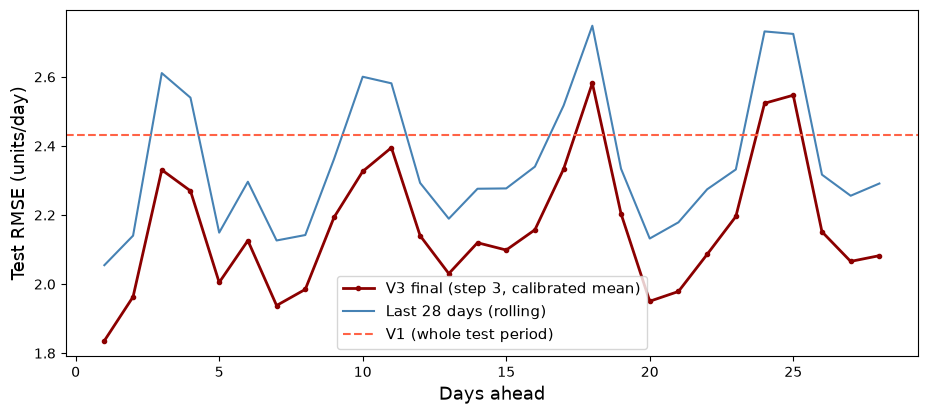

In [19]:
def rmse_by_day_ahead(pred):
    sq = np.where(test_mask, (pred - y_test)**2, 0)
    return np.sqrt(pd.Series(sq.sum(axis=0)).groupby(day_ahead).sum()
                   / pd.Series(test_mask.sum(axis=0)).groupby(day_ahead).sum())

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(rmse_by_day_ahead(pred_best), color='darkred', linewidth=2, marker='o', markersize=3,
        label='V3 final (step 3, calibrated mean)')
ax.plot(rmse_by_day_ahead(roll_last28), color='steelblue', linewidth=1.5, label='Last 28 days (rolling)')
ax.axhline(results_df.loc['V1 TimesFM (with covariates, mean)', 'RMSE'], color='tomato', linestyle='--',
           label='V1 (whole test period)')
ax.set_xlabel('Days ahead', fontsize=13)
ax.set_ylabel('Test RMSE (units/day)', fontsize=13)
ax.legend(fontsize=11)
plt.show()

### Accuracy by Category

In [20]:
rows = []
for cat in ['FOODS', 'HOUSEHOLD', 'HOBBIES']:
    in_cat = (sales_wide['cat_id'] == cat).to_numpy()
    m = test_mask & in_cat[:, None]
    row = {'Category': cat, 'Series': in_cat.sum()}
    for name, pred in [('V1', v1_mean), ('Last 28 days (rolling)', roll_last28), ('V3 final', pred_best)]:
        row[f'OSR² {name}'] = osr2(pred[m], y_test[m], y_train_mean)
    rows.append(row)
display(pd.DataFrame(rows).set_index('Category').round(3))

,Series,OSR² V1,OSR² Last 28 days (rolling),OSR² V3 final
Category,,,,
FOODS,14370,0.571,0.593,0.666
HOUSEHOLD,10470,0.521,0.572,0.606
HOBBIES,5650,0.394,0.425,0.437


### Forecasting Total Sales

Adding up the item forecasts gives a forecast of total daily sales. We compare V1 and V3 with the actual totals; Christmas Day, when stores are closed, is left out of the percentage error.

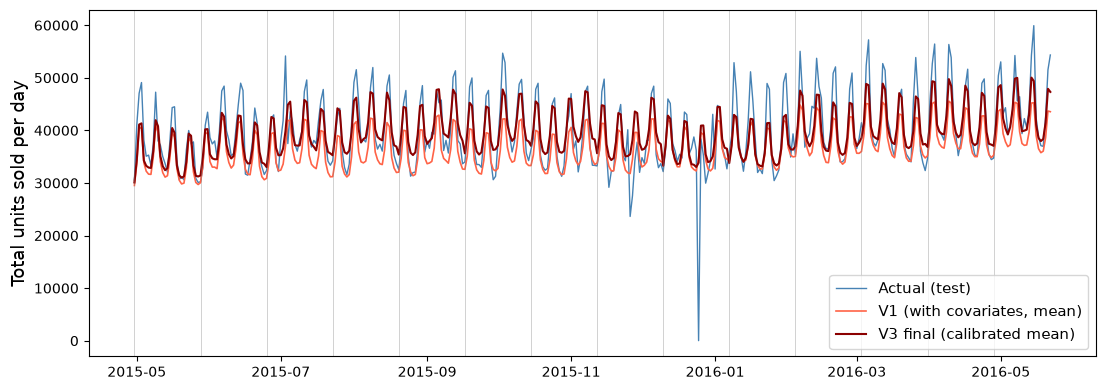

,Total test units,Bias,Daily MAPE
Forecast,,,
Actual,"15,485,627",,
"V1 (with covariates, mean)","14,252,372",-8.0%,8.6%
Last 28 days (rolling),"15,262,894",-1.4%,12.5%
"V3 step 3, median","11,748,517",-24.1%,23.9%
"V3 step 3, quantile average","14,405,060",-7.0%,7.8%
V3 final (calibrated mean),"15,364,162",-0.8%,6.5%


In [21]:
total_actual = np.where(test_mask, y_test, 0).sum(axis=0)
totals = {name: np.where(test_mask, pred, 0).sum(axis=0) for name, pred in [
    ('V1 (with covariates, mean)', v1_mean),
    ('Last 28 days (rolling)', roll_last28),
    ('V3 step 3, median', pred_s3),
    ('V3 step 3, quantile average', q_s3.mean(axis=2)),
    ('V3 final (calibrated mean)', pred_best)]}

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(dates[n_train_days:], total_actual, color='steelblue', linewidth=1, label='Actual (test)')
ax.plot(dates[n_train_days:], totals['V1 (with covariates, mean)'], color='tomato', linewidth=1.2,
        label='V1 (with covariates, mean)')
ax.plot(dates[n_train_days:], totals['V3 final (calibrated mean)'], color='darkred', linewidth=1.5,
        label='V3 final (calibrated mean)')
for origin in origins:
    ax.axvline(dates[origin], color='grey', linewidth=0.5, alpha=0.5)
ax.set_ylabel('Total units sold per day', fontsize=13)
ax.legend(fontsize=11)
plt.show()

keep = pd.to_datetime(dates[n_train_days:]).strftime('%m-%d') != '12-25'
rows = [{'Forecast': 'Actual', 'Total test units': total_actual.sum()}]
for name, total in totals.items():
    rows.append({'Forecast': name, 'Total test units': total.sum(),
                 'Bias': total.sum() / total_actual.sum() - 1,
                 'Daily MAPE': np.mean(np.abs(total - total_actual)[keep] / total_actual[keep])})
display(pd.DataFrame(rows).set_index('Forecast').style.format(
    {'Total test units': '{:,.0f}', 'Bias': '{:+.1%}', 'Daily MAPE': '{:.1%}'}, na_rep=''))

### Example Forecasts

The three panels show the best-seller, a typical series and the slowest seller with a training history, with the actual test sales, the final V3 forecast and its 80% prediction interval (between the 10% and 90% quantiles). The vertical lines mark the forecast dates.

/tmp/ipykernel_1645604/2312232065.py:1: RuntimeWarning: Mean of empty slice
  series_mean = np.nanmean(np.where(train_mask, y_train, np.nan), axis=1)


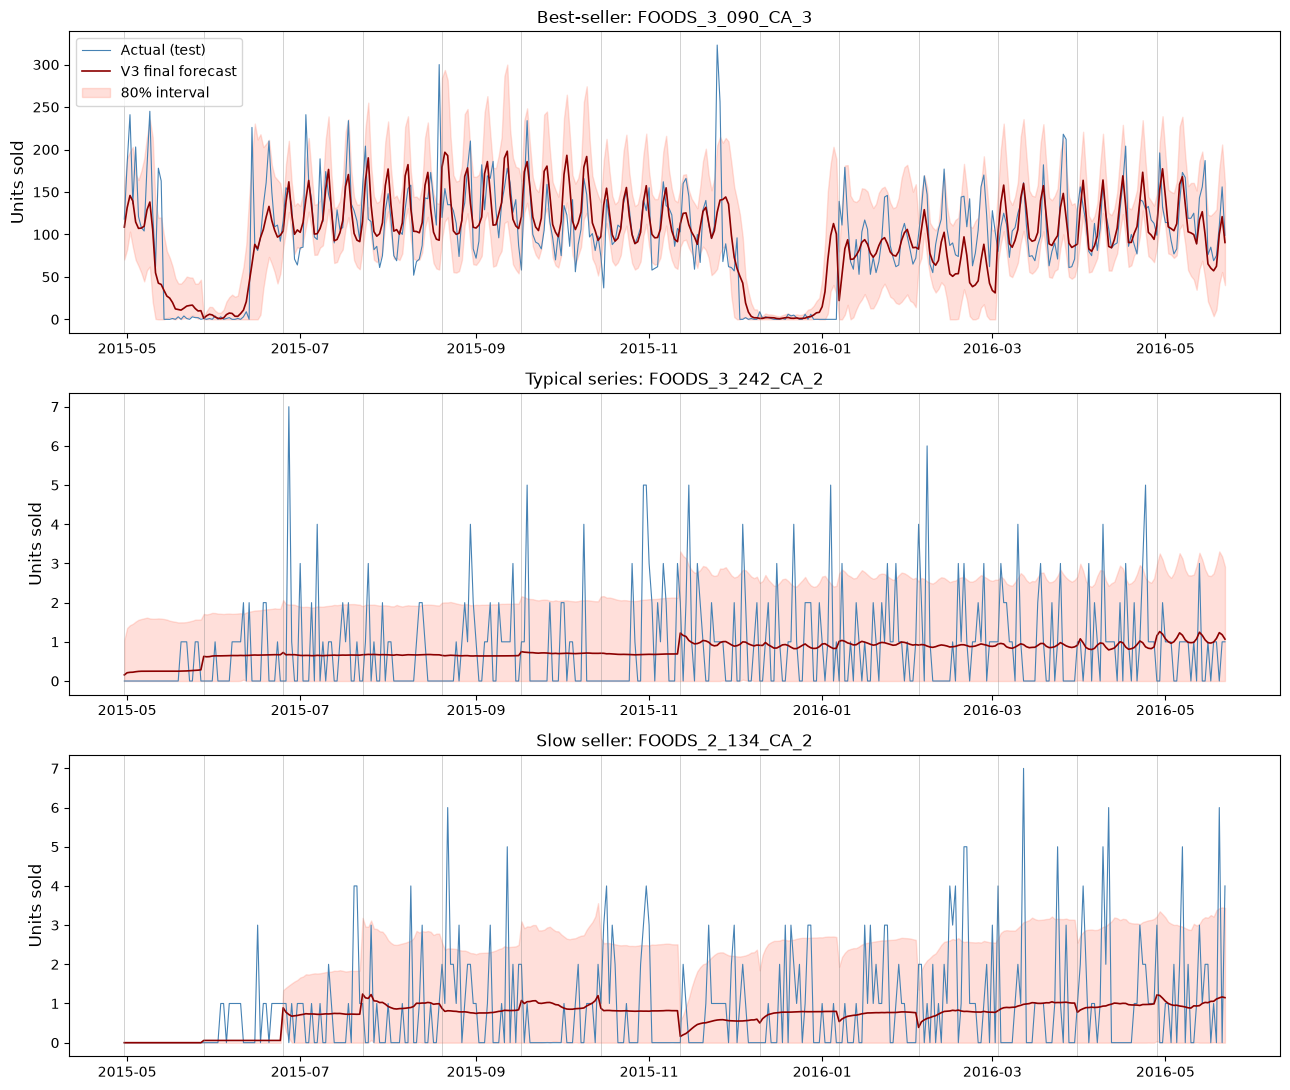

In [22]:
series_mean = np.nanmean(np.where(train_mask, y_train, np.nan), axis=1)
has_history = np.flatnonzero(~np.isnan(series_mean))     # series on sale in the training period
rank = has_history[np.argsort(series_mean[has_history])]
fig, axes = plt.subplots(3, 1, figsize=(13, 11))
for ax, i, label in zip(axes, [rank[-1], rank[n_series // 2], rank[0]],
                        ['Best-seller', 'Typical series', 'Slow seller']):
    ax.plot(dates[n_train_days:], y_test[i], color='steelblue', linewidth=0.8, label='Actual (test)')
    ax.plot(dates[n_train_days:], pred_best[i], color='darkred', linewidth=1.2, label='V3 final forecast')
    ax.fill_between(dates[n_train_days:], q_s3[i, :, 0], q_s3[i, :, -1], color='tomato', alpha=0.2,
                    label='80% interval')
    for origin in origins:
        ax.axvline(dates[origin], color='grey', linewidth=0.5, alpha=0.5)
    ax.set_title(f"{label}: {sales_wide.loc[i, 'id'].replace('_evaluation', '')}", fontsize=12)
    ax.set_ylabel('Units sold', fontsize=12)
axes[0].legend(fontsize=10, loc='upper left')
plt.tight_layout()
plt.show()

### Checking the Prediction Intervals

As in V1, we check whether the actual sales fall inside the 80% interval on about 80% of the test observations.

In [23]:
for name, q in [('Step 1: rolling', q_s1), ('Step 3: + discount, SNAP, major events', q_s3)]:
    lo, hi = q[:, :, 0][test_mask], q[:, :, -1][test_mask]
    print(f"{name}")
    print(f"  Below the 10% quantile: {np.mean(y_test_obs < lo):.1%}")
    print(f"  Above the 90% quantile: {np.mean(y_test_obs > hi):.1%}")
    print(f"  Inside the 80% interval: {np.mean((y_test_obs >= lo) & (y_test_obs <= hi)):.1%}")

Step 1: rolling
  Below the 10% quantile: 6.9%
  Above the 90% quantile: 8.6%
  Inside the 80% interval: 84.5%
Step 3: + discount, SNAP, major events
  Below the 10% quantile: 8.0%
  Above the 90% quantile: 9.1%
  Inside the 80% interval: 82.8%


## Takeaways of Part 1 (V3 Baseline)

**V3 is the best TimesFM model on all 30,490 series.** The final model (rolling forecasts, stock-out cleaning, discount and major-event covariates, calibrated mean) reaches a test **OSR² of 0.642**, an RMSE of **2.17** units and a **WRMSSE of 0.744**, against 0.551, 2.43 and 0.957 for the V1 model, on the same 11.8 million test observations. It also beats the rolling 28-day average (OSR² 0.578, WRMSSE 1.073) and the rolling seasonal naive forecast (0.543, 0.815), and it beats the rolling 28-day average in every product category: FOODS 0.666, HOUSEHOLD 0.606, HOBBIES 0.437 (against 0.593, 0.572 and 0.425).

**Step 1, rolling forecasts, brings the largest gain.** Re-forecasting every 4 weeks with the latest sales raises OSR² from 0.551 (V1) to **0.619** with the quantile-average forecast, even without any covariates. No test day is now forecast more than 28 days ahead.

**Step 2, stock-out cleaning, helps on all series.** The rule cleaned 16.2% of the history days, in 24,121 of the 30,490 series, and raised the OSR² of the quantile average from 0.619 to **0.631** (WRMSSE 0.874 → 0.860; 0.802 → 0.778 for the calibrated mean). With the 6,638 regular sellers, the same step barely moved OSR². The slow and intermittent sellers have more and longer gaps in their history, and many of them are listed but out of stock for weeks; filling these gaps gives TimesFM a more realistic sales level. The rule can still fill runs that are not stock-outs (an item taken off the shelf for a long time), so a cap on the length of a stock-out would be a sensible refinement.

**Step 3, the discount and major-event covariates, adds a consistent gain.** OSR² rises by about 0.01 (0.631 → 0.641 with the quantile average) and WRMSSE falls from 0.860 to 0.830 (0.778 → 0.744 for the calibrated mean). The four major events (Christmas, Thanksgiving, New Year and Labor Day, each moving total sales by 15% or more) are rare, but the model now gets these days right. The discount captures promotions, which affect 7.6% of the test series-days.

**Step 4, the calibrated mean, matters for WRMSSE rather than for OSR².** For daily item sales, the calibrated mean and the plain average of the quantiles are equivalent (OSR² 0.6415 and 0.6410). The difference is in the totals: the calibrated mean forecasts total test-period sales **within 0.8%** of the actual total (−7.0% for the quantile average, −24.1% for the median, −8.0% for V1), and WRMSSE falls from 0.830 to **0.744**.

**What WRMSSE adds.** OSR² and WRMSSE rank some models differently. The rolling 28-day average has a better OSR² than the seasonal naive forecast (0.578 vs 0.543) but a much worse WRMSSE (1.073 vs 0.815): a flat forecast misses the weekly cycle, which is small for one item but large for a store or a state total. The TimesFM **median** is the extreme case: a reasonable OSR² (0.61–0.63) but a very poor WRMSSE (1.49–1.61), because it underestimates total sales by about 24%. For a slow seller the median day sells nothing, so the median forecast is close to 0 for most series, and these misses add up in every total.

**What MAE and WAPE add.** The two absolute-error measures reward the **median**, not the mean: the TimesFM median has the best MAE (0.90 units) and WAPE (68.5%) of all models, while the calibrated mean, the best on OSR² and WRMSSE, has an MAE of 0.99 and a WAPE of 75.5%. Which forecast is "best" therefore depends on the cost of an error: squared-error and hierarchy measures favor the mean, which gets the totals right; absolute-error measures favor the median, which is right more often on a single day but too low in total. For inventory planning, where the totals drive orders, the calibrated mean is the better choice. A WAPE around 75% is typical for daily item-store forecasts of slow sellers: the average series-day sells only 1.3 units.

**The prediction intervals remain usable, a little wide.** Actual sales fall inside the 80% interval on 82.8% of test observations for the final model (84.5% for step 1).

**Comparison with the M5 competition.** Our WRMSSE of 0.744 is 9% below the rolling seasonal naive forecast (0.815). It cannot be compared directly with the M5 winner's 0.520: we average 14 windows over a year that include Christmas and Thanksgiving (the competition scored one window in May–June 2016), and we forecast with TimesFM zero-shot rather than with models trained on M5.

**What to try next.** V3 points to three ideas, which Part 2 tests as scenarios: (A) combine TimesFM with a regression model, using the TimesFM forecast as a feature; (B) fine-tune TimesFM on the M5 training period; (C) add a different type of model, such as the gradient-boosted trees used by the M5 winners, and average the two.

# Part 2: Scenario Analysis

V3 is the baseline. Each scenario below changes **one aspect** of how the forecasts are made and keeps everything else fixed: all 30,490 series, the 80% / 20% time split, the 14 forecast dates, the **28-day forecast horizon** and the five metrics. The scenarios start from the V3 TimesFM forecasts computed above; none of them runs TimesFM again on the test period.

| Scenario | Question | What changes |
|---|---|---|
| **A (V4)** | Can a regression learned across all series correct TimesFM? | TimesFM forecast becomes a feature of a LASSO model |
| **B (V5)** | Does TimesFM gain from learning on Walmart data? | TimesFM's output layer is fine-tuned on the training period |
| **C (V6)** | Does a second, different model add information? | Ensemble of TimesFM with a recursive gradient-boosted model |

## Scenario A (V4): A Hybrid Model, TimesFM Forecast as a LASSO Feature

**What the scenario is.** We **stack** the two families of models used in this project: the TimesFM forecast becomes **one more feature** of a LASSO regression, next to recent sales, last year's sales, the discount, SNAP, events, the weekday, the category, the department and the store. LASSO learns how much to trust TimesFM and how to adjust it.

**Why we add this scenario.** TimesFM and the regression models of the earlier notebooks are good at different things:

| | TimesFM | LASSO regression |
|---|---|---|
| Each item's own pattern (level, trend, weekly cycle) | strong | only what the features capture |
| Learning across all 30,490 series at once | no: each series is forecast on its own | yes: one model for all series |
| Effects of discounts, SNAP and events | weak: learned per series, from few examples | learned from hundreds of thousands of rows |
| Correcting TimesFM's systematic errors | no | yes, through the coefficient of the TimesFM feature |

If the two make different mistakes, the hybrid should beat both. This scenario also tests the idea in the V3 takeaways of using the TimesFM forecast as a feature in the regression model.

**Forecast task.** Unchanged: on each of the 14 forecast dates, forecast the next **28 days**. Every feature is known on the forecast date (sales up to that date, last year's sales, planned prices and the calendar), never sales inside the window being forecast.

In [24]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# The V3 final forecast (Step 3, calibrated mean) is the benchmark for every scenario
pred_v3 = pred_best

### Building the Features

Each observation is one **series on one test day**. Every feature must be **known on the forecast date** of that day's window: we may use sales up to the forecast date, last year's sales, and the planned calendar and prices, but never sales inside the window being forecast.

| Group | Features | Meaning |
|---|---|---|
| **TimesFM** | `tfm_s3`, `tfm_s1` | average of the 9 quantiles, V3 Step 3 and Step 1 |
| | `tfm_q10`, `tfm_q90` | 10% and 90% quantiles of Step 3: the forecast uncertainty |
| Recent sales | `roll7`, `roll28` | average daily sales over the 7 and 28 days before the forecast date |
| | `snaive` | average of the last 4 weeks on the same weekday |
| Last year | `lag364`, `ly7` | sales on the same weekday 52 weeks earlier, and the 7-day average around it |
| Price and calendar | `discount`, `price`, `snap`, `days_ahead` | discount from the regular price, price, SNAP day in the store's state, days ahead (1–28) |
| Interactions | `tfm_x_days_ahead`, `roll7_x_days_ahead` | let the weight of TimesFM and of recent sales change with the horizon |
| | `tfm_x_HOBBIES`, `tfm_x_HOUSEHOLD` | let the weight of TimesFM differ by category |
| Indicators | event name, event type, month, weekday, category, department, store | one-hot encoded, baseline level dropped, as in the regression notebooks |

We do not use item or item-store indicators: with only a few hundred test-period rows per series, their coefficients would be noisy, and the TimesFM and recent-sales features already capture each series' level.

In [25]:
# price_filled, regular_price, discount and state are defined in V3 Step 3
snap = np.stack([cal[f'snap_{s}'].to_numpy(dtype=np.float32) for s in state])

# Recent sales, as known on each forecast date
roll7, roll28, snaive = (np.zeros((n_series, horizon), dtype=np.float32) for _ in range(3))
for origin in origins:
    h = min(WINDOW, T - origin)
    cols = slice(origin - n_train_days, origin - n_train_days + h)
    roll7[:, cols] = units[:, origin - 7:origin].mean(axis=1, keepdims=True)
    roll28[:, cols] = units[:, origin - 28:origin].mean(axis=1, keepdims=True)
    snaive[:, cols] = np.tile(units[:, origin - 28:origin].reshape(n_series, 4, 7).mean(axis=1), 4)[:, :h]

# Last year: 364 days earlier is the same weekday, and always before the forecast date
test_days = np.arange(n_train_days, T)
lag364 = units[:, test_days - 364]
ly7 = np.stack([units[:, t - 367:t - 360].mean(axis=1) for t in test_days], axis=1)

numeric = {
    'tfm_s3': q_s3.mean(axis=2), 'tfm_s1': q_s1.mean(axis=2),
    'tfm_q10': q_s3[:, :, 0], 'tfm_q90': q_s3[:, :, -1],
    'roll7': roll7, 'roll28': roll28, 'snaive': snaive, 'lag364': lag364, 'ly7': ly7,
    'discount': discount[:, n_train_days:], 'price': price_filled[:, n_train_days:],
    'snap': snap[:, n_train_days:],
    'days_ahead': np.broadcast_to(day_ahead, (n_series, horizon)).astype(np.float32),
}
numeric['tfm_x_days_ahead'] = numeric['tfm_s3'] * numeric['days_ahead']
numeric['roll7_x_days_ahead'] = numeric['roll7'] * numeric['days_ahead']
for c in ['HOBBIES', 'HOUSEHOLD']:
    numeric[f'tfm_x_{c}'] = numeric['tfm_s3'] * (sales_wide['cat_id'].to_numpy() == c)[:, None]

# One-hot indicators, baseline level dropped. Calendar indicators vary by day, the others by series.
indicators = {}
cal_test = cal.iloc[n_train_days:]
for col, base in [('event_name_1', 'No_Event'), ('event_type_1', 'No_Event'), ('month', '1'), ('weekday', 'Monday')]:
    values = cal_test[col].fillna('No_Event').astype(str).to_numpy()
    for level in sorted(set(values) - {base}):
        indicators[f'{col}_{level}'] = np.broadcast_to((values == level).astype(np.float32), (n_series, horizon))
for col, base in [('cat_id', 'FOODS'), ('dept_id', 'FOODS_1'), ('store_id', 'CA_1')]:
    values = sales_wide[col].to_numpy()
    for level in sorted(set(values) - {base}):
        indicators[f'{col}_{level}'] = np.broadcast_to((values == level).astype(np.float32)[:, None],
                                                       (n_series, horizon))

features = {**numeric, **indicators}
all_features = list(features)
tfm_features = [f for f in all_features if f.startswith('tfm')]
print(f"Features: {len(numeric)} numeric + {len(indicators)} indicators = {len(all_features)} "
      f"({len(tfm_features)} built from TimesFM)")

def design_matrix(mask, feature_names):
    rows, cols = np.nonzero(mask)
    X = np.column_stack([features[f][rows, cols] for f in feature_names]).astype(np.float32)
    return X, rows, cols

Features: 17 numeric + 68 indicators = 85 (7 built from TimesFM)


### Fitting the LASSO Window by Window

The TimesFM forecasts exist only for the test period, so the LASSO is trained on test windows whose sales are **already known**: the model that predicts window $k$ is fitted on windows $1, \dots, k-1$, exactly as the V3 calibrated mean was. This is an **expanding window**: the training data grow from 28 days (for window 2) to 336 days (for window 14). Window 1 has no earlier window, so it keeps the V3 forecast (the plain average of the quantiles, as in V3).

**Choosing $\lambda$.** For each window, we hold out a random 20% of the **series** from the training windows, fit the LASSO on the other 80% for 8 values of $\lambda$, keep the value with the lowest validation error, and refit on all the training rows. As in the regression notebooks, the features are standardized first, so that the penalty treats them equally. Holding out whole series (rather than the most recent window) gives a stable choice of $\lambda$: a single 28-day window is dominated by its own holidays and shocks.

To keep the fits fast, each training set is a random sample of at most 300,000 rows. Predictions are clipped at 0.

In [26]:
ALPHAS = np.exp(np.linspace(-1, -8, 8))       # from strong to weak regularization
MAX_ROWS = 300_000

def rolling_lasso(feature_names, label, seed=71):
    rng = np.random.default_rng(seed)
    pred = q_s3.mean(axis=2).copy()           # window 1: V3 quantile average
    chosen = []
    t0 = time.time()
    for k in range(1, len(origins)):
        X, rows, _ = design_matrix(test_mask & (window_of_day < k)[None, :], feature_names)
        y = y_test[test_mask & (window_of_day < k)[None, :]]
        if len(y) > MAX_ROWS:
            keep = rng.choice(len(y), MAX_ROWS, replace=False)
            X, y, rows = X[keep], y[keep], rows[keep]

        # Choose lambda on a 20% hold-out of the series
        valid = np.isin(rows, rng.choice(n_series, n_series // 5, replace=False))
        model = make_pipeline(StandardScaler(), Lasso(max_iter=5000, tol=1e-3, warm_start=True))
        errors = []
        for alpha in ALPHAS:
            model.set_params(lasso__alpha=alpha).fit(X[~valid], y[~valid])
            errors.append(np.mean((np.clip(model.predict(X[valid]), 0, None) - y[valid])**2))
        alpha = ALPHAS[int(np.argmin(errors))]

        # Refit on all training rows and predict window k
        model = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=5000, tol=1e-3)).fit(X, y)
        X_new, r, c = design_matrix(test_mask & (window_of_day == k)[None, :], feature_names)
        pred[r, c] = np.clip(model.predict(X_new), 0, None)
        chosen.append({'Window': k + 1, 'Training rows': len(y), 'log(λ)': np.log(alpha),
                       'Features kept': int(np.sum(model[-1].coef_ != 0))})
    print(f"{label}: {len(origins) - 1} windows fitted in {time.time() - t0:.0f} s")
    return pred, model, pd.DataFrame(chosen).set_index('Window')

### Three LASSO Models

To see where the gain comes from, we fit three LASSO models with the same procedure:

1. **LASSO without TimesFM**: all features except the TimesFM ones. This is a regression model in the style of the earlier notebooks, but on the V3 task (1 to 28 days ahead, time split).
2. **LASSO on TimesFM features only**: the 4 TimesFM features and their 3 interactions. This combines the TimesFM forecasts, but adds no other information.
3. **Hybrid**: all features.

In [27]:
features_no_tfm = [f for f in all_features if f not in tfm_features]

pred_lasso, model_lasso, lambdas_lasso = rolling_lasso(features_no_tfm, 'LASSO without TimesFM')
pred_tfm_only, model_tfm_only, _ = rolling_lasso(tfm_features, 'LASSO on TimesFM features only')
pred_hybrid, model_hybrid, lambdas_hybrid = rolling_lasso(all_features, 'Hybrid (TimesFM + all features)')

print("\nHybrid: lambda and features kept in each window")
display(lambdas_hybrid.round(2))

LASSO without TimesFM: 13 windows fitted in 117 s


LASSO on TimesFM features only: 13 windows fitted in 14 s


Hybrid (TimesFM + all features): 13 windows fitted in 170 s

Hybrid: lambda and features kept in each window


,Training rows,log(λ),Features kept
Window,,,
2,300000,-6.0,39
3,300000,-8.0,47
4,300000,-2.0,7
5,300000,-8.0,50
6,300000,-5.0,35
7,300000,-6.0,44
8,300000,-6.0,54
9,300000,-6.0,50
10,300000,-5.0,41


### Results

#### Model Comparison

All models are scored on the same test observations. Window 1 is identical for all the LASSO models and V3 (no earlier window to learn from), so we also report the OSR² on windows 2–14 alone, where the LASSO models actually differ.

,OSR²,RMSE,MAE,WAPE,WRMSSE,"OSR², windows 2–14"
Model,,,,,,
Training mean,0.0000,3.6304,1.7461,1.3339,2.4512,
"V3 TimesFM (step 3, quantile average)",0.6410,2.1753,0.9564,0.7306,0.8300,0.6420
"V3 TimesFM final (step 3, calibrated mean)",0.6415,2.1736,0.9878,0.7546,0.7438,0.6426
LASSO without TimesFM,0.6159,2.2499,1.0173,0.7771,0.8351,0.6152
LASSO on TimesFM features only,0.6409,2.1755,0.9877,0.7546,0.7609,0.6419
Hybrid: TimesFM + LASSO,0.6424,2.1709,0.9880,0.7548,0.7290,0.6435


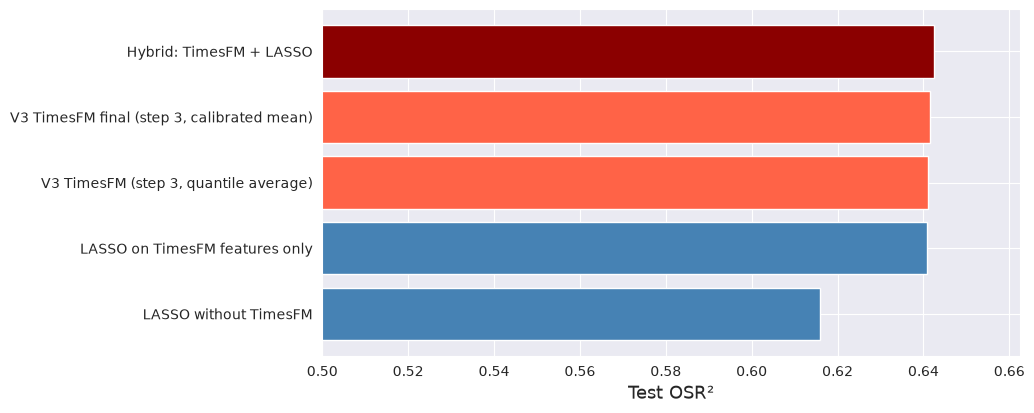

In [28]:
models_v4 = [('V3 TimesFM (step 3, quantile average)', q_s3.mean(axis=2)),
          ('V3 TimesFM final (step 3, calibrated mean)', pred_v3),
          ('LASSO without TimesFM', pred_lasso),
          ('LASSO on TimesFM features only', pred_tfm_only),
          ('Hybrid: TimesFM + LASSO', pred_hybrid)]

later = test_mask & (window_of_day >= 1)[None, :]
results_v4 = [evaluate('Training mean', np.full_like(y_test, y_train_mean))]
for name, pred in models_v4:
    row = evaluate(name, pred)
    row['OSR², windows 2–14'] = osr2(pred[later], y_test[later], y_train_mean)
    results_v4.append(row)

results_v4_df = pd.DataFrame(results_v4).set_index('Model')
display(results_v4_df.round(4).style
        .highlight_max(subset=['OSR²', 'OSR², windows 2–14'], color='lightgreen')
        .highlight_min(subset=['RMSE', 'MAE', 'WAPE', 'WRMSSE'], color='lightgreen')
        .format('{:.4f}', na_rep=''))

plot_df = results_v4_df.drop('Training mean').reset_index().sort_values('OSR²')
colors = ['darkred' if m.startswith('Hybrid') else 'tomato' if m.startswith('V3') else 'steelblue'
          for m in plot_df['Model']]
sns.set_style('darkgrid')
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_df['Model'], plot_df['OSR²'], color=colors)
ax.set_xlim(0.5, plot_df['OSR²'].max() + 0.02)
ax.set_xlabel('Test OSR²', fontsize=13)
plt.show()

#### What the Hybrid Learned

The table shows the coefficients of the hybrid model fitted for the last window (trained on windows 1–13), for the standardized features, so that their sizes are comparable: each coefficient is the change in predicted daily sales for a one-standard-deviation change in the feature. The features set to zero by LASSO are not shown.

In [29]:
coefs = pd.Series(model_hybrid[-1].coef_, index=all_features)
coefs = coefs[coefs != 0]
print(f"Features kept: {len(coefs)} of {len(all_features)} | intercept {model_hybrid[-1].intercept_:.3f}")
display(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(20)
        .to_frame('Standardized coefficient').round(3))

Features kept: 69 of 85 | intercept 1.292


,Standardized coefficient
tfm_s3,1.090
tfm_q90,0.652
tfm_s1,0.375
ly7,0.305
tfm_q10,0.260
roll7,0.256
event_name_1_Christmas,-0.060
snaive,0.059
weekday_Sunday,0.059
weekday_Saturday,0.048


#### Accuracy by Days Ahead and by Category

In [30]:
def osr2_where(pred, mask):
    return osr2(pred[mask], y_test[mask], y_train_mean)

rows = []
for lo, hi in [(1, 7), (8, 14), (15, 21), (22, 28)]:
    m = later & ((day_ahead >= lo) & (day_ahead <= hi))[None, :]
    rows.append({'Days ahead': f'{lo}–{hi}', **{name: osr2_where(p, m) for name, p in models_v4[1:]}})
print("OSR² by days ahead (windows 2–14)")
display(pd.DataFrame(rows).set_index('Days ahead').round(4))

rows = []
for cat in ['FOODS', 'HOUSEHOLD', 'HOBBIES']:
    m = later & (sales_wide['cat_id'] == cat).to_numpy()[:, None]
    rows.append({'Category': cat, **{name: osr2_where(p, m) for name, p in models_v4[1:]}})
print("OSR² by category (windows 2–14)")
display(pd.DataFrame(rows).set_index('Category').round(4))

OSR² by days ahead (windows 2–14)


,"V3 TimesFM final (step 3, calibrated mean)",LASSO without TimesFM,LASSO on TimesFM features only,Hybrid: TimesFM + LASSO
Days ahead,,,,
1–7,0.6682,0.6336,0.6679,0.6683
8–14,0.6542,0.6277,0.6544,0.6557
15–21,0.6318,0.6064,0.6312,0.6332
22–28,0.6151,0.5922,0.6130,0.6158


OSR² by category (windows 2–14)


,"V3 TimesFM final (step 3, calibrated mean)",LASSO without TimesFM,LASSO on TimesFM features only,Hybrid: TimesFM + LASSO
Category,,,,
FOODS,0.6676,0.6387,0.6669,0.6692
HOUSEHOLD,0.6044,0.5828,0.6052,0.6039
HOBBIES,0.4382,0.4174,0.4360,0.4357


#### Forecasting Total Sales

As in V3, we add up the forecasts of all series for each day and compare with the actual total. Christmas Day (when the stores are closed) is left out of the daily percentage error.

,Bias,Daily MAPE
Forecast,,
"V3 TimesFM (step 3, quantile average)",-7.0%,7.8%
"V3 TimesFM final (step 3, calibrated mean)",-0.8%,6.5%
LASSO without TimesFM,-0.5%,7.3%
LASSO on TimesFM features only,-0.8%,6.9%
Hybrid: TimesFM + LASSO,-0.9%,6.2%


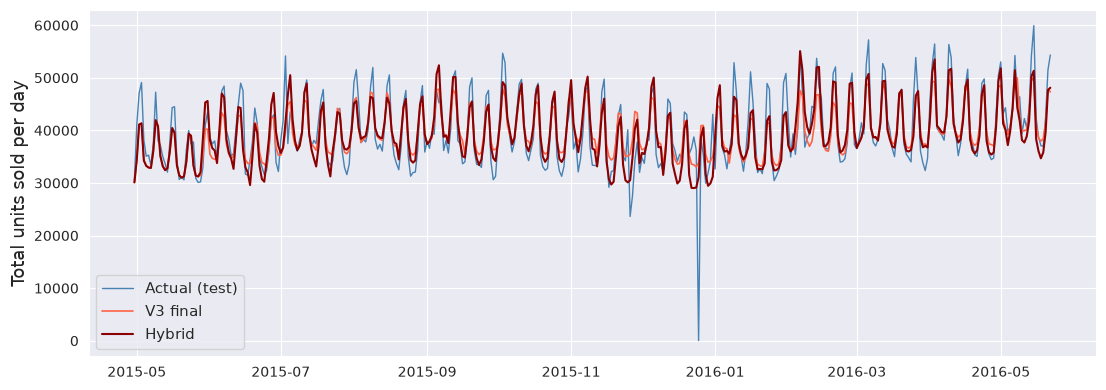

In [31]:
total_actual = np.where(test_mask, y_test, 0).sum(axis=0)
keep = pd.to_datetime(dates[n_train_days:]).strftime('%m-%d') != '12-25'
rows = []
for name, pred in models_v4:
    total = np.where(test_mask, pred, 0).sum(axis=0)
    rows.append({'Forecast': name, 'Bias': total.sum() / total_actual.sum() - 1,
                 'Daily MAPE': np.mean(np.abs(total - total_actual)[keep] / total_actual[keep])})
display(pd.DataFrame(rows).set_index('Forecast').style.format('{:+.1%}', subset=['Bias'])
        .format('{:.1%}', subset=['Daily MAPE']))

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(dates[n_train_days:], total_actual, color='steelblue', linewidth=1, label='Actual (test)')
ax.plot(dates[n_train_days:], np.where(test_mask, pred_v3, 0).sum(axis=0), color='tomato', linewidth=1.2,
        label='V3 final')
ax.plot(dates[n_train_days:], np.where(test_mask, pred_hybrid, 0).sum(axis=0), color='darkred', linewidth=1.5,
        label='Hybrid')
ax.set_ylabel('Total units sold per day', fontsize=13)
ax.legend(fontsize=11)
plt.show()

#### Scenario A (V4): Key Takeaways

1. **On all series, the hybrid improves both OSR² and WRMSSE, slightly.** Stacking the TimesFM forecasts with recent sales, last year's sales, price, SNAP, events and the calendar in a LASSO raises the test OSR² from **0.6415 (V3 final) to 0.6424**, lowers RMSE from 2.174 to 2.171, and lowers the **WRMSSE from 0.744 to 0.729 (−2.0%)**. MAE (0.988) and WAPE (75.5%) are unchanged. The hybrid is at least as good as V3 at every horizon from 1 to 28 days ahead. With the 6,638 regular sellers, the same hybrid worsened WRMSSE.

2. **The gain is in the totals, not the items.** By level, the hybrid improves every aggregate level (Total 0.632 → 0.579, Store 0.680 → 0.654), but is equal or slightly worse at the three item levels (Item 0.858 → 0.862). The LASSO, fitted on all series at once, learns calendar and event effects that are shared by all items, which add up in the totals. Its total-sales bias stays small (−0.9%, against −0.8% for V3).

3. **TimesFM is the core of the hybrid.** The LASSO **without** TimesFM features reaches 0.616 (WRMSSE 0.835), well above the rolling 28-day average (0.578) but clearly below TimesFM (0.642). With them, the largest coefficients belong to TimesFM features (`tfm_s3`, `tfm_q90`, `tfm_s1`, `tfm_q10`). A LASSO on the TimesFM features alone already reaches 0.641: the other features add about 0.001 on top.

4. **What the other features contribute.** The largest non-TimesFM coefficients are **last year's sales** (`ly7`) and the **last week's sales** (`roll7`): TimesFM sees only the last 1,024 days and benefits from a direct reminder of last year's level for the same week. The negative `tfm_x_days_ahead` coefficient means the model **trusts TimesFM a little less further ahead**. Discount and SNAP add almost nothing beyond what TimesFM already uses as covariates.

5. **Why the gain is small.** The TimesFM forecast already summarizes each series' level, trend and weekly cycle, which is most of what the other features describe. A **linear** model can only reweight and shift the TimesFM forecast; it cannot learn interactions. And the LASSO is trained on the test windows already observed, so its first windows learn from only 28 to 84 days of data.

**Verdict for Scenario A:** a small but consistent gain on all series (+0.001 OSR², −2.0% WRMSSE), coming from the aggregate levels.

## Scenario B (V5): Fine-Tuning TimesFM's Output Head on M5

**What the scenario is.** So far TimesFM has been used **zero-shot**: its pretrained weights were never trained on Walmart data. This scenario tests the cheapest form of **fine-tuning**: we train only the model's **output head**, its last layer, on M5 sales from the training period, and keep the other 330 million parameters frozen.

```
History → input layer → 20 transformer layers → 1,280-number summary z → OUTPUT HEAD → 64 days × 9 quantiles
          (frozen)       (frozen)                                            (trained here)
```

**Why we add this scenario.** Scenario A adjusts TimesFM *from the outside*, with a linear model. Fine-tuning changes TimesFM *itself*. Retail sales have features that are rare in TimesFM's pretraining data, such as many zero days, small integer counts and strong weekly cycles, so a model that has seen M5 might forecast them better. The output head is the natural first layer to train: it decides how the model's internal summary is turned into the 9 quantile forecasts, so it can correct systematic bias and recalibrate the quantiles. Training only the head is cheap enough to run on a laptop and can be checked exactly against the library's forecasts.

**Forecast task.** Unchanged: the head is trained and evaluated on **28-day forecasts**. We keep the 252 head outputs for days 1–28 (28 days × 9 quantiles) and ignore the outputs for days 29–64. The baseline is the univariate V3 model (Step 1), since the fine-tuned model also uses past sales only.

**How the forecast is built from the head.** Reading the TimesFM code, the forecast of a series for future day $t$ and quantile $q$ is

$$\hat y_{t,q} = \text{head}(z)_{t,q} \times S + B_t,$$

then sorted across quantiles and clipped at 0, where the scale $S$ and the offset $B_t$ (the series' level and linear trend) are fixed by its history. Because everything before the head is frozen, we only need to run TimesFM **once** per forecast date to save $z$, $S$ and $B_t$ for every series. Fine-tuning then runs on these saved numbers in seconds. With the pretrained head, this rebuilds the library's forecasts exactly, which we check below.

**What can and cannot change.** The head can correct systematic bias, recalibrate the quantiles for M5, and re-weight the patterns the frozen layers already detect. It cannot make the model notice patterns it does not already see.

### Forecast Dates: Fine-Tuning, Validation and Test

Fine-tuning must use **training-period data only**, so that the test set stays untouched. We split the forecast dates three ways:

| Set | Forecast dates (last history day) | Days forecast | Use |
|---|---|---|---|
| **Fine-tuning** | 12 dates, every 28 days, from `d_1104` to `d_1412` | `d_1105` – `d_1440`, about one year | train the head |
| **Validation** | 4 dates: `d_1440`, `d_1468`, `d_1496`, `d_1524` | `d_1441` – `d_1552`, the last 16 weeks of training | choose the settings and the stopping epoch |
| **Test** | the 14 V3 dates, from `d_1552` to `d_1916` | `d_1553` – `d_1941` | final evaluation, as in V3 |

Every forecast uses the last 1,024 days of history before its date, as in V3. Each example is one series at one forecast date: about 366,000 fine-tuning examples (12 × 30,490) and 122,000 validation examples.

In [32]:
test_origins = origins
valid_origins = np.arange(n_train_days - 4*WINDOW, n_train_days, WINDOW)
fit_origins = np.arange(n_train_days - 16*WINDOW, n_train_days - 4*WINDOW, WINDOW)
print(f"Fine-tuning dates: {len(fit_origins)} | validation dates: {len(valid_origins)} | test dates: {len(test_origins)}")

Fine-tuning dates: 12 | validation dates: 4 | test dates: 14


### Saving the Frozen Features

For each forecast date, we run TimesFM once (univariate, `use_symmetric_averaging=False`, as in V3 Step 1) and capture, for every series:

- **`z`**: the 1,280 numbers that enter the output head for the last history block. We read them with a PyTorch *forward hook*, which records a layer's input without changing the computation.
- **`S` and `B`**: the scale and the offset (level and trend) that turn the head's output into units sold. We recover them from the de-normalized forecast the model returns.
- **`q_library`**: the library's own 9 quantile forecasts, used to check our reconstruction.

One forecast date of all 30,490 series takes about 1 minute on the cluster's L40S GPU, so the 30 dates take about 30 minutes. Each date is **saved to its own file** in the folder `timesfm3_v5_features_all30490`, so running the notebook again reads the files instead.

In [33]:
FEATURE_DIR = os.path.join(os.getcwd(), 'timesfm3_v5_features_all30490')
os.makedirs(FEATURE_DIR, exist_ok=True)

head = forecaster.model.output_head
W0 = head.weight.detach().float().cpu().numpy()       # (576, 1280): 64 days x 9 quantiles
b0 = head.bias.detach().float().cpu().numpy()          # (576,)

# Capture (1) the input of the output head at the last history block and (2) the
# de-normalized forecast returned by decode(), before sorting and clipping.
captured = {'z': [], 'head_out': [], 'decoded': []}

def capture_head(module, inputs, output):
    # Blocks are ordered: history blocks, then 2 future blocks. The forecast is read
    # from the last history block, which is the third block from the end.
    captured['z'].append(inputs[0][:, 0, -3, :].float().cpu().numpy())
    captured['head_out'].append(output[:, 0, -3, :].float().cpu().numpy())

hook = head.register_forward_hook(capture_head)
_original_decode = forecaster.model.decode
def decode_and_capture(*args, **kwargs):
    out = _original_decode(*args, **kwargs)
    captured['decoded'].append(out[:, 0].float().cpu().numpy())
    return out
forecaster.model.decode = decode_and_capture

def extract_features(origin):
    # Frozen TimesFM pass at one forecast date: summary z, scale S and offset B per series.
    path = os.path.join(FEATURE_DIR, f'origin_{origin}.npz')
    if os.path.isfile(path):
        return dict(np.load(path))
    for v in captured.values():
        v.clear()
    contexts = [units[i, context_start(i, origin):origin] for i in range(n_series)]
    outs = list(forecaster.predict_batch(contexts, horizon=WINDOW, return_quantiles=True,
                                         use_symmetric_averaging=False, make_positive=True))
    z = np.concatenate(captured['z'])
    head_out = np.concatenate(captured['head_out']).reshape(n_series, 64, 9)
    decoded = np.concatenate(captured['decoded'])
    # decoded = head_out x S + B[day]: recover S (one per series) and B (one per series and day)
    hc = head_out - head_out.mean(axis=2, keepdims=True)
    dc = decoded - decoded.mean(axis=2, keepdims=True)
    S = (hc * dc).sum(axis=(1, 2)) / (hc**2).sum(axis=(1, 2))
    B = decoded.mean(axis=2) - S[:, None] * head_out.mean(axis=2)
    q_library = np.stack([o.quantiles for o in outs])
    features = {'z': z.astype(np.float32), 'S': S.astype(np.float32),
                'B': B[:, :WINDOW].astype(np.float32), 'q_library': q_library.astype(np.float32)}
    np.savez(path, **features)
    return features

t0 = time.time()
for origin in list(test_origins) + list(valid_origins) + list(fit_origins):
    extract_features(int(origin))
print(f"Features ready for {len(test_origins) + len(valid_origins) + len(fit_origins)} forecast dates "
      f"({time.time() - t0:.0f} s)")

# The features are saved: remove the hook and restore the original decode()
hook.remove()
forecaster.model.decode = _original_decode

Features ready for 30 forecast dates (13 s)


### The Fine-Tuning Procedure

**Loss.** TimesFM was pretrained with the **quantile (pinball) loss**, which penalizes a forecast of quantile $q$ by $q \times$ the shortfall when the actual is higher and $(1-q) \times$ the excess when it is lower. We keep this loss so that the 9 outputs remain quantiles. Days on which the item was not on sale are left out.

**Weighting of the series.** Two choices:
- **`units`**: the loss in units sold, so that high-volume series count more. This matches OSR² and RMSE, which are dominated by the large sellers.
- **`normalized`**: the loss divided by each series' scale $S$, so that every series counts the same, as in pretraining. Series whose history is all zeros have $S = 0$ and are left out of this loss (their forecast does not depend on the head).

**Optimization.** We start from the **pretrained weights** of the 252 head rows used for days 1–28 and update them with the Adam optimizer, in mini-batches of 2,048 examples, for up to 30 passes (epochs) over the fine-tuning set. After each epoch we compute the **validation MSE of the mean forecast** (the average of the 9 quantiles), the quantity that OSR² rewards, and keep the epoch with the lowest value (**early stopping**).

The hyperparameters we compare are the series weighting and the **learning rate**, the size of each update. We also tried a ridge penalty pulling the weights toward their pretrained values; it did not help in our trials, so it is left at 0 here (`penalty` argument).

In [34]:
QUANTILES = torch.tensor([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
ROWS = WINDOW * 9                                  # head rows used: 28 days x 9 quantiles

def stack_origins(origin_list):
    # Training examples (one per series and forecast date) from the saved features.
    Z, S, B, Y, M = [], [], [], [], []
    for origin in origin_list:
        f = extract_features(int(origin))
        h = min(WINDOW, T - origin)
        y = np.zeros((n_series, WINDOW), dtype=np.float32)
        m = np.zeros((n_series, WINDOW), dtype=bool)
        y[:, :h], m[:, :h] = units[:, origin:origin + h], on_sale[:, origin:origin + h]
        Z.append(f['z']); S.append(f['S']); B.append(f['B']); Y.append(y); M.append(m)
    return {k: torch.from_numpy(np.concatenate(v)) for k, v in
            zip(['Z', 'S', 'B', 'Y', 'M'], [Z, S, B, Y, M])}

def head_forecast(data, W, b):
    # The library's forecast with head weights (W, b): head output x S + B, sorted, clipped at 0
    out = (data['Z'] @ W.T + b).view(-1, WINDOW, 9) * data['S'][:, None, None] + data['B'][:, :, None]
    return out

def finalize(out):
    return torch.clamp(torch.sort(out, dim=2).values, min=0)

def pinball(out, data, weighting):
    err = data['Y'][:, :, None] - out
    loss = torch.maximum(QUANTILES * err, (QUANTILES - 1) * err).mean(dim=2)   # (n, 28)
    if weighting == 'normalized':
        # each series counts the same, as in pretraining. Series with an all-zero history have scale 0:
        # their forecast does not depend on the head, so they are left out instead of dividing by 0.
        S = data['S'][:, None]
        loss = torch.where(S > 0, loss / S.clamp(min=1e-6), torch.zeros_like(loss))
    return (loss * data['M']).sum() / data['M'].sum()

def fine_tune_head(train, valid, weighting='units', penalty=0.0, lr=1e-4, epochs=20,
                   batch_size=2048, seed=71, verbose=False):
    # Train the 252 head rows used for days 1-28, starting from the pretrained weights.
    # penalty: ridge penalty on the change from the pretrained weights.
    torch.manual_seed(seed)
    W_init = torch.from_numpy(W0[:ROWS].copy())
    b_init = torch.from_numpy(b0[:ROWS].copy())
    W = W_init.clone().requires_grad_(True)
    b = b_init.clone().requires_grad_(True)
    opt = torch.optim.Adam([W, b], lr=lr)
    n = len(train['Y'])
    history, best = [], (np.inf, None, None, 0)
    for epoch in range(epochs + 1):
        if epoch > 0:
            perm = torch.randperm(n)
            for start in range(0, n, batch_size):
                idx = perm[start:start + batch_size]
                batch = {k: v[idx] for k, v in train.items()}
                loss = pinball(head_forecast(batch, W, b), batch, weighting)
                if penalty > 0:
                    loss = loss + penalty * ((W - W_init)**2).sum()
                opt.zero_grad()
                loss.backward()
                opt.step()
        with torch.no_grad():
            v_out = head_forecast(valid, W, b)
            v_loss = pinball(v_out, valid, 'units').item()
            v_mse = mse_of_mean(finalize(v_out), valid)
        history.append({'Epoch': epoch, 'Validation pinball loss': v_loss, 'Validation MSE (mean)': v_mse})
        if verbose:
            print(f"  epoch {epoch:2d}: validation pinball {v_loss:.4f} | MSE of mean {v_mse:.4f}")
        if v_mse < best[0]:
            best = (v_mse, W.detach().clone(), b.detach().clone(), epoch)
    return best[1], best[2], best[3], pd.DataFrame(history).set_index('Epoch')

def mse_of_mean(q, data):
    # MSE of the mean forecast (average of the 9 sorted, clipped quantiles) on on-sale days
    err = (q.mean(dim=2) - data['Y'])**2
    return ((err * data['M']).sum() / data['M'].sum()).item()

ft_train = stack_origins(fit_origins)
ft_valid = stack_origins(valid_origins)
ft_test = stack_origins(test_origins)
print(f"Examples: fine-tuning {len(ft_train['Y']):,} | validation {len(ft_valid['Y']):,} | test {len(ft_test['Y']):,}")

# Check: the pretrained head rebuilds the library's forecasts
W_pre, b_pre = torch.from_numpy(W0[:ROWS].copy()), torch.from_numpy(b0[:ROWS].copy())
first = extract_features(int(test_origins[0]))
rebuilt = finalize(head_forecast(stack_origins(test_origins[:1]), W_pre, b_pre)).numpy()
print(f"Largest difference between our rebuilt forecasts and the library's: {np.abs(rebuilt - first['q_library']).max():.6f} units")

Examples: fine-tuning 365,880 | validation 121,960 | test 426,860


Largest difference between our rebuilt forecasts and the library's: 0.000122 units


### Choosing the Settings on the Validation Set

We fine-tune with each combination of series weighting and learning rate, and compare them on the **validation** set only. For transparency we also print the test OSR² of each, but the choice is made on validation, as it would have to be in practice.

In [35]:
def test_quantiles(W, b):
    # Fine-tuned forecasts on the test windows, arranged as (series, test day, quantile)
    with torch.no_grad():
        q_windows = finalize(head_forecast(ft_test, W, b)).numpy().reshape(len(test_origins), n_series, WINDOW, 9)
    q = np.zeros((n_series, horizon, 9), dtype=np.float32)
    for k, origin in enumerate(test_origins):
        h = min(WINDOW, T - origin)
        q[:, origin - n_train_days:origin - n_train_days + h] = q_windows[k, :, :h]
    return q

with torch.no_grad():
    valid_mse_pretrained = mse_of_mean(finalize(head_forecast(ft_valid, W_pre, b_pre)), ft_valid)
q_pretrained = test_quantiles(W_pre, b_pre)

runs = [{'Weighting': 'pretrained head (no fine-tuning)', 'Learning rate': np.nan, 'Best epoch': 0,
         'Validation MSE': valid_mse_pretrained,
         'Test OSR² (mean)': evaluate('', q_pretrained.mean(axis=2))['OSR²']}]
fitted = {}
for weighting in ['units', 'normalized']:
    for lr in [3e-4, 1e-3, 3e-3]:
        t0 = time.time()
        W, b, epoch, hist = fine_tune_head(ft_train, ft_valid, weighting=weighting, lr=lr, epochs=30)
        fitted[(weighting, lr)] = (W, b, hist)
        runs.append({'Weighting': weighting, 'Learning rate': lr, 'Best epoch': epoch,
                     'Validation MSE': hist['Validation MSE (mean)'].min(),
                     'Test OSR² (mean)': evaluate('', test_quantiles(W, b).mean(axis=2))['OSR²']})
        print(f"  {weighting}, learning rate {lr:g}: {time.time() - t0:.0f} s")

runs_df = pd.DataFrame(runs)
display(runs_df.round({'Validation MSE': 4, 'Test OSR² (mean)': 4}).style
        .highlight_min(subset=['Validation MSE'], color='lightgreen').format(precision=4, na_rep=''))

best_run = runs_df.iloc[1:]['Validation MSE'].idxmin()
chosen = (runs_df.loc[best_run, 'Weighting'], runs_df.loc[best_run, 'Learning rate'])
W_ft, b_ft, hist_ft = fitted[chosen]
print(f"Chosen on validation: weighting = {chosen[0]}, learning rate = {chosen[1]:g}")

  units, learning rate 0.0003: 33 s


  units, learning rate 0.001: 29 s


  units, learning rate 0.003: 30 s


  normalized, learning rate 0.0003: 31 s


  normalized, learning rate 0.001: 29 s


  normalized, learning rate 0.003: 31 s


,Weighting,Learning rate,Best epoch,Validation MSE,Test OSR² (mean)
0,pretrained head (no fine-tuning),,0,5.1572,0.6191
1,units,0.0003,30,4.9253,0.6300
2,units,0.0010,30,4.8760,0.6333
3,units,0.0030,24,4.8479,0.6313
4,normalized,0.0003,28,4.9570,0.6314
5,normalized,0.0010,23,4.9184,0.6328
6,normalized,0.0030,23,4.9083,0.6328


Chosen on validation: weighting = units, learning rate = 0.003


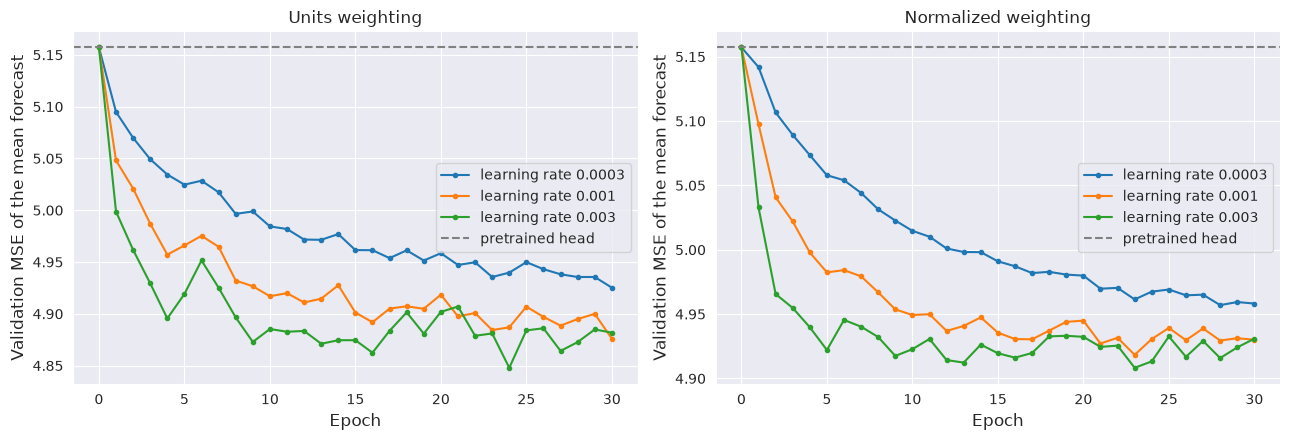

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (weighting, lr), (_, _, hist) in fitted.items():
    axes[0 if weighting == 'units' else 1].plot(hist.index, hist['Validation MSE (mean)'], marker='o',
                                                 markersize=3, label=f'learning rate {lr:g}')
for ax, title in zip(axes, ['Units weighting', 'Normalized weighting']):
    ax.axhline(valid_mse_pretrained, color='grey', linestyle='--', label='pretrained head')
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Epoch', fontsize=12)
    ax.set_ylabel('Validation MSE of the mean forecast', fontsize=12)
    ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

#### Test Results

We compare the fine-tuned head (chosen on validation) with the pretrained head, which is exactly V3 Step 1, and with the final V3 model (Step 3 with covariates, calibrated mean).

In [37]:
q_ft = test_quantiles(W_ft, b_ft)

models_v5 = {
    'Pretrained head = V3 Step 1 (median)': q_pretrained[:, :, 4],
    'Pretrained head = V3 Step 1 (quantile average)': q_pretrained.mean(axis=2),
    'Fine-tuned head (median)': q_ft[:, :, 4],
    'Fine-tuned head (quantile average)': q_ft.mean(axis=2),
    'V3 final (step 3, calibrated mean)': pred_v3,
}
results_v5_df = pd.DataFrame([evaluate('Training mean', np.full_like(y_test, y_train_mean))] +
                             [evaluate(name, pred) for name, pred in models_v5.items()]).set_index('Model')
display(results_v5_df.round(4).style.highlight_max(subset=['OSR²'], color='lightgreen')
        .highlight_min(subset=['RMSE', 'MAE', 'WAPE', 'WRMSSE'], color='lightgreen').format('{:.4f}'))

,OSR²,RMSE,MAE,WAPE,WRMSSE
Model,,,,,
Training mean,0.0000,3.6304,1.7461,1.3339,2.4512
Pretrained head = V3 Step 1 (median),0.6095,2.2688,0.8988,0.6867,1.6125
Pretrained head = V3 Step 1 (quantile average),0.6191,2.2405,0.9660,0.7380,0.8740
Fine-tuned head (median),0.6100,2.2672,0.9029,0.6898,1.8501
Fine-tuned head (quantile average),0.6313,2.2045,0.9534,0.7284,1.0420
"V3 final (step 3, calibrated mean)",0.6415,2.1736,0.9878,0.7546,0.7438


#### Accuracy by Days Ahead, by Category, and Interval Coverage

In [38]:
def osr2_where(pred, mask):
    return osr2(pred[mask], y_test[mask], y_train_mean)

pairs = [('Pretrained head', q_pretrained), ('Fine-tuned head', q_ft)]
rows = []
for lo, hi in [(1, 7), (8, 14), (15, 21), (22, 28)]:
    m = test_mask & ((day_ahead >= lo) & (day_ahead <= hi))[None, :]
    rows.append({'Days ahead': f'{lo}–{hi}', **{n: osr2_where(q.mean(axis=2), m) for n, q in pairs}})
print("OSR² of the quantile average, by days ahead")
display(pd.DataFrame(rows).set_index('Days ahead').round(4))

rows = []
for cat in ['FOODS', 'HOUSEHOLD', 'HOBBIES']:
    m = test_mask & (sales_wide['cat_id'] == cat).to_numpy()[:, None]
    rows.append({'Category': cat, **{n: osr2_where(q.mean(axis=2), m) for n, q in pairs}})
print("OSR² of the quantile average, by category")
display(pd.DataFrame(rows).set_index('Category').round(4))

rows = []
total_actual_sum = np.where(test_mask, y_test, 0).sum()
for name, q in pairs:
    lo, hi = q[:, :, 0][test_mask], q[:, :, -1][test_mask]
    rows.append({'Model': name, 'Below 10% quantile': np.mean(y_test_obs < lo),
                 'Above 90% quantile': np.mean(y_test_obs > hi),
                 'Inside 80% interval': np.mean((y_test_obs >= lo) & (y_test_obs <= hi)),
                 'Total sales bias (quantile average)': np.where(test_mask, q.mean(axis=2), 0).sum() / total_actual_sum - 1})
print("Calibration of the quantiles (target: 10% below, 10% above, 80% inside)")
display(pd.DataFrame(rows).set_index('Model').style.format('{:.1%}'))

change = np.linalg.norm(W_ft.numpy() - W_pre.numpy()) / np.linalg.norm(W_pre.numpy())
print(f"Relative change of the head weights: {change:.1%}")

OSR² of the quantile average, by days ahead


,Pretrained head,Fine-tuned head
Days ahead,,
1–7,0.6681,0.6636
8–14,0.6380,0.6419
15–21,0.5970,0.6123
22–28,0.5703,0.6055


OSR² of the quantile average, by category


,Pretrained head,Fine-tuned head
Category,,
FOODS,0.6437,0.6563
HOUSEHOLD,0.6008,0.5981
HOBBIES,0.3880,0.4212


Calibration of the quantiles (target: 10% below, 10% above, 80% inside)


,Below 10% quantile,Above 90% quantile,Inside 80% interval,Total sales bias (quantile average)
Model,,,,
Pretrained head,6.9%,8.6%,84.5%,-7.6%
Fine-tuned head,4.8%,10.6%,84.6%,-13.5%


Relative change of the head weights: 20.1%


#### Scenario B (V5): Key Takeaways

1. **Fine-tuning the output head is technically sound, and cheap.** Our rebuilt forecasts match the library's to within 0.0001 units, so the fine-tuning trains exactly the forecast that TimesFM produces. Once the features are saved (about 30 minutes on the cluster GPU, once), each fine-tuning run takes about 30 seconds on a CPU.

2. **On all series, it improves item-level accuracy.** Every setting lowered the validation MSE, by up to 6.0% (5.157 → 4.848), and the setting chosen on validation (units weighting, learning rate 0.003) raises the test OSR² of the quantile average from **0.619 (pretrained head, V3 Step 1) to 0.631**, with a lower MAE (0.966 → 0.953) and WAPE (73.8% → 72.8%). All six settings land between 0.630 and 0.633. The gain is largest far ahead (0.570 → 0.606 at 22–28 days) and for HOBBIES (0.388 → 0.421), where TimesFM's pretrained head fits the slow, intermittent sellers worst. With the 6,638 regular sellers, fine-tuning gave no gain at all.

3. **But it forecasts too low in total, so WRMSSE gets much worse.** The fine-tuned head moves the quantiles down: fewer actual sales fall below its 10% quantile (6.9% → 4.8%), more fall above its 90% quantile (8.6% → 10.6%), and total test sales are underestimated by **13.5%** instead of 7.6%. The WRMSSE rises from 0.874 to **1.042** (+19%), worse at every aggregate level (Total 0.843 → 1.124) and better only at the item-store level (0.981 → 0.922). The head learned that most series-days sell less than TimesFM expects, which is true day by day for slow sellers, but it does not keep the total right.

4. **The head changed much more than on the regular sellers.** The weights moved by 20% (5.7% with the 6,638 regular sellers): intermittent series are further from what TimesFM saw in pretraining, so there is more to correct.

5. **Implications.** The fine-tuned head is a good starting point **if the bias is corrected**, for example with the calibrated mean of V3 Step 4 on top of the fine-tuned quantiles, or by fine-tuning with a loss that also penalizes the error of the totals. Fine-tuning on several years and validating on a full year would also reduce the risk of learning a period-specific level.

**Verdict for Scenario B:** a real item-level gain on all series (+0.012 OSR² against its univariate baseline), but not usable as it is because of its large under-forecast of totals (WRMSSE +19%).

## Scenario C (V6): Ensemble with a Recursive Gradient-Boosted Model, Weighted by Horizon

**What the scenario is.** We build a second forecaster of a different kind and average it with TimesFM:

1. **A recursive gradient-boosted tree model.** One model for all 30,490 series predicts **tomorrow's** sales from the recent days (lags of 1 to 7, 14, 21 and 28 days, rolling averages, days since the last sale), last year's sales, price, SNAP, events and the calendar. To forecast 28 days, it predicts day 1, **writes that forecast into the history as if it were real**, predicts day 2 from it, and so on up to day 28.
2. **A horizon-weighted ensemble.** The final forecast is a weighted average of the two models, with a separate weight for each range of days ahead (day 1, days 2–3, 4–7, 8–14 and 15–28). The weights are learned only from forecast windows whose sales are already known.

**Why we add this scenario.** Gradient-boosted trees (LightGBM) trained on lag, price and calendar features, with recursive multi-step forecasts, were the core of most **top M5 solutions**, including the winner. Scenario A combined TimesFM with a *linear* model, which cannot learn interactions such as "discounts matter more for this department in this store"; trees can. TimesFM forecasts **directly** (all 28 days in one pass), while the recursive model rebuilds its features day by day, so the two models use the same history in different ways. An ensemble helps only if they make **different errors**; this scenario measures how different they are.

**Gradient-boosted trees.** We use scikit-learn's `HistGradientBoostingRegressor`, which implements the same histogram-based algorithm as LightGBM (LightGBM itself needs the OpenMP system library, which is not installed on this computer). We use the **Poisson loss**, suited to sales counts.

**Forecast task.** Unchanged: on each of the 14 forecast dates the tree model is refitted on data up to that date and forecasts the next **28 days** recursively. Only its own forecasts, never the actual sales of the window, are fed back as lags.

In [39]:
from sklearn.ensemble import HistGradientBoostingRegressor

pred_tfm = pred_v3
results_v6 = [evaluate('Training mean', np.full_like(y_test, y_train_mean)),
              evaluate('V3 TimesFM final (calibrated mean)', pred_tfm)]

### The Recursive Gradient-Boosted Model

#### Features

Each training row is **one series on one day**, and the target is that day's sales. All features are known the evening before:

| Group | Features |
|---|---|
| Recent sales | sales 1, 2, …, 7, 14, 21 and 28 days before; averages of the last 7 and 28 days; average of the same weekday over the last 4 weeks |
| Stock-out signal | days since the last day with sales (capped at 60) |
| Last year | sales 364 days before (same weekday) and the 7-day average around it |
| Item level | the series' average daily sales over the training period |
| Price and promotions | discount from the regular (median training) price, price, SNAP day in the store's state |
| Calendar | weekday, month, day of the month, event type, event name |
| Item and store | category, department, store |

The calendar, item and store features are declared **categorical**, so the trees split on their levels directly, without one-hot encoding.

#### Training and forecasting

On each of the 14 forecast dates, we fit a new model on **1 million randomly drawn series-days from the two years before that date**, using only actual sales. Then we forecast the next 28 days **recursively**: on day 2 the lag-1 feature is the model's own forecast of day 1, on day 3 the lag-1 and lag-2 features are forecasts, and so on. Last year's sales and the calendar, prices and events are known in advance and never need forecasting.

Settings: Poisson loss, 300 trees, learning rate 0.08, at most 127 leaves per tree, at least 100 rows per leaf, L2 penalty 1. Each forecast date takes about 15 seconds on 16 cluster CPU cores, and the forecasts are **saved** in the folder `timesfm3_v6_gbm_all30490`.

In [40]:
GBM_ROWS, GBM_TREES, GBM_LR, GBM_LEAVES = 1_000_000, 300, 0.08, 127

LAGS = [1, 2, 3, 4, 5, 6, 7, 14, 21, 28]
DSL_CAP = 60

# Static inputs: known in advance (calendar, planned prices) or fixed per series
price_filled = pd.DataFrame(price).ffill(axis=1).bfill(axis=1).to_numpy(dtype=np.float32)
regular_price = np.nanmedian(np.where(on_sale[:, :n_train_days], price[:, :n_train_days], np.nan), axis=1)
# Series first on sale after the training period: their first price is the regular price
regular_price = np.where(np.isnan(regular_price), price[np.arange(n_series), first_day], regular_price)
discount = (1 - price_filled / regular_price[:, None]).astype(np.float32)
state = sales_wide['state_id'].to_numpy()
snap = np.stack([cal[f'snap_{s}'].to_numpy(dtype=np.float32) for s in state])
weekday = cal['wday'].to_numpy()
month = cal['month'].to_numpy()
day_of_month = pd.to_datetime(cal['date']).dt.day.to_numpy()
event_type = pd.Categorical(cal['event_type_1'].fillna('None')).codes
event_name = pd.Categorical(cal['event_name_1'].fillna('None')).codes
cat_code = pd.Categorical(sales_wide['cat_id']).codes
dept_code = pd.Categorical(sales_wide['dept_id']).codes
store_code = pd.Categorical(sales_wide['store_id']).codes
series_mean = np.nanmean(np.where(on_sale[:, :n_train_days], units[:, :n_train_days], np.nan), axis=1)

def days_since_sale(x):
    # Days since the last day with sales above 0.5 units, before each day (capped)
    out = np.zeros(x.shape, dtype=np.float32)
    run = np.full(x.shape[0], DSL_CAP, dtype=np.float32)
    for t in range(x.shape[1]):
        out[:, t] = run
        run = np.where(x[:, t] > 0.5, 1, np.minimum(run + 1, DSL_CAP))
    return out

GBM_FEATURES = ([f'lag{k}' for k in LAGS] + ['roll7', 'roll28', 'same_weekday_4w', 'days_since_sale',
                'lag364', 'last_year_7d', 'series_mean', 'discount', 'price', 'snap',
                'weekday', 'month', 'day_of_month', 'event_type', 'event_name', 'cat', 'dept', 'store'])
CATEGORICAL = ['weekday', 'month', 'event_type', 'event_name', 'cat', 'dept', 'store']

def gbm_features(work, dsl, s, t):
    # Features of series s on day t, from the sales array `work` (actuals, or forecasts in the recursion)
    cols = [work[s, t - k] for k in LAGS]
    cum = lambda a, b: work_cum[s, b] - work_cum[s, a]       # sum of work[s, a:b]
    cols += [cum(t - 7, t) / 7, cum(t - 28, t) / 28,
             (work[s, t - 7] + work[s, t - 14] + work[s, t - 21] + work[s, t - 28]) / 4,
             dsl[s, t], units[s, t - 364], (units_cum[s, t - 360] - units_cum[s, t - 367]) / 7,
             series_mean[s], discount[s, t], price_filled[s, t], snap[s, t],
             weekday[t], month[t], day_of_month[t], event_type[t], event_name[t],
             cat_code[s], dept_code[s], store_code[s]]
    return np.column_stack(cols).astype(np.float32)

units_cum = np.hstack([np.zeros((n_series, 1), dtype=np.float64), np.cumsum(units, axis=1)])
dsl_actual = days_since_sale(units)

def fit_gbm(origin, rng, n_rows=GBM_ROWS):
    # Train on a random sample of on-sale series-days in the 2 years before the forecast date
    global work_cum
    work_cum = units_cum
    s = rng.integers(0, n_series, n_rows * 2)
    t = rng.integers(origin - 728, origin, n_rows * 2)
    keep = on_sale[s, t] & (t - 28 >= first_day[s])
    s, t = s[keep][:n_rows], t[keep][:n_rows]
    X = gbm_features(units, dsl_actual, s, t)
    model = HistGradientBoostingRegressor(
        loss='poisson', learning_rate=GBM_LR, max_iter=GBM_TREES, max_leaf_nodes=GBM_LEAVES,
        min_samples_leaf=100, l2_regularization=1.0,
        categorical_features=[GBM_FEATURES.index(c) for c in CATEGORICAL], early_stopping=False,
        random_state=71)
    return model.fit(X, units[s, t])

def recursive_forecast(model, origin, h):
    # Predict day 1, write it into the history, predict day 2 from it, ... up to day h
    global work_cum
    work = units.copy()
    work[:, origin:] = 0
    dsl = dsl_actual.copy()
    s = np.arange(n_series)
    run = dsl_actual[:, origin].copy()
    preds = np.zeros((n_series, h), dtype=np.float32)
    for d in range(h):
        t = origin + d
        dsl[:, t] = run
        work_cum = np.hstack([np.zeros((n_series, 1)), np.cumsum(work[:, :t + 1], axis=1)])
        p = model.predict(gbm_features(work, dsl, s, np.full(n_series, t)))
        preds[:, d] = p
        work[:, t] = p
        run = np.where(p > 0.5, 1, np.minimum(run + 1, DSL_CAP))
    return preds

GBM_CACHE_DIR = os.path.join(os.getcwd(), 'timesfm3_v6_gbm_all30490')
os.makedirs(GBM_CACHE_DIR, exist_ok=True)

rng = np.random.default_rng(71)
pred_gbm = np.zeros((n_series, horizon), dtype=np.float32)
t0 = time.time()
for k, origin in enumerate(origins):
    h = min(WINDOW, T - origin)
    path = os.path.join(GBM_CACHE_DIR, f'gbm_origin{k:02d}.npy')
    if os.path.isfile(path):
        p = np.load(path)
    else:
        p = recursive_forecast(fit_gbm(origin, rng), origin, h)
        np.save(path, p)
        print(f"  forecast date {k + 1}/{len(origins)} done | {time.time() - t0:.0f} s")
    pred_gbm[:, origin - n_train_days:origin - n_train_days + h] = p

results_v6.append(evaluate('Recursive gradient-boosted trees', pred_gbm))
display(pd.DataFrame(results_v6).round(4))

~/envs/tfm/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,


/tmp/ipykernel_1645604/2060300921.py:22: RuntimeWarning: Mean of empty slice
  series_mean = np.nanmean(np.where(on_sale[:, :n_train_days], units[:, :n_train_days], np.nan), axis=1)


,Model,OSR²,RMSE,MAE,WAPE,WRMSSE
0,Training mean,0.0000,3.6304,1.7461,1.3339,2.4512
1,V3 TimesFM final (calibrated mean),0.6415,2.1736,0.9878,0.7546,0.7438
2,Recursive gradient-boosted trees,0.5730,2.3723,0.9912,0.7573,0.6485


### Comparing the Two Models by Days Ahead

How useful the ensemble can be depends on where each model is strong, and on how much their errors differ.

In [41]:
BUCKETS = [(1, 1), (2, 3), (4, 7), (8, 14), (15, 28)]
bucket_of_day = np.zeros(horizon, dtype=int)
for j, (lo, hi) in enumerate(BUCKETS):
    bucket_of_day[(day_ahead >= lo) & (day_ahead <= hi)] = j

def osr2_where(pred, mask):
    return osr2(pred[mask], y_test[mask], y_train_mean)

rows = []
for j, (lo, hi) in enumerate(BUCKETS):
    m = test_mask & (bucket_of_day == j)[None, :]
    e_t, e_g = (pred_tfm - y_test)[m], (pred_gbm - y_test)[m]
    rows.append({'Days ahead': f'{lo}–{hi}' if hi > lo else f'{lo}',
                 'OSR² TimesFM': osr2_where(pred_tfm, m), 'OSR² recursive GBM': osr2_where(pred_gbm, m),
                 'Correlation of errors': np.corrcoef(e_t, e_g)[0, 1]})
display(pd.DataFrame(rows).set_index('Days ahead').round(4))

,OSR² TimesFM,OSR² recursive GBM,Correlation of errors
Days ahead,,,
1,0.6627,0.6213,0.9297
2–3,0.7002,0.6506,0.9093
4–7,0.6550,0.6118,0.9116
8–14,0.6558,0.6028,0.8999
15–28,0.6187,0.5298,0.8758


### The Horizon-Weighted Ensemble

For each range of days ahead $b$, the ensemble forecast is

$$\hat y = w_b \cdot \hat y_{\text{GBM}} + (1 - w_b) \cdot \hat y_{\text{TimesFM}}, \qquad 0 \le w_b \le 1.$$

The weights must be learned on sales that are already known. As for the V3 calibrated mean, the weights used in window $k$ are chosen on windows $1, \dots, k-1$: for each range of days ahead, the $w_b$ (on a grid of steps of 0.05) with the lowest squared error. Window 1 has no earlier window, so it uses TimesFM alone.

We also show two other versions:
- **One weight for all horizons**, learned the same way, to see whether horizon-specific weights help.
- **Weights chosen on the test set itself**: this is *not* a valid forecast, because it uses the test sales to set the weights. It shows the best any such ensemble could do, an upper bound.

In [42]:
GRID = np.round(np.arange(0, 1.0001, 0.05), 2)

def best_weight(mask):
    sse = [np.sum((w*pred_gbm[mask] + (1 - w)*pred_tfm[mask] - y_test[mask])**2) for w in GRID]
    return GRID[int(np.argmin(sse))]

pred_ens, pred_ens_one = pred_tfm.copy(), pred_tfm.copy()
weights = []
for k in range(1, len(origins)):
    known = test_mask & (window_of_day < k)[None, :]
    row = {'Window': k + 1, 'One weight': best_weight(known)}
    cols = window_of_day == k
    pred_ens_one[:, cols] = row['One weight']*pred_gbm[:, cols] + (1 - row['One weight'])*pred_tfm[:, cols]
    for j, (lo, hi) in enumerate(BUCKETS):
        w = best_weight(known & (bucket_of_day == j)[None, :])
        row[f'Days {lo}–{hi}' if hi > lo else f'Day {lo}'] = w
        c = cols & (bucket_of_day == j)
        pred_ens[:, c] = w*pred_gbm[:, c] + (1 - w)*pred_tfm[:, c]
    weights.append(row)
weights_df = pd.DataFrame(weights).set_index('Window')
print("Weight of the recursive GBM, learned on the earlier windows")
display(weights_df)

pred_oracle = pred_tfm.copy()
oracle_w = {}
for j, (lo, hi) in enumerate(BUCKETS):
    c = bucket_of_day == j
    oracle_w[j] = best_weight(test_mask & c[None, :])
    pred_oracle[:, c] = oracle_w[j]*pred_gbm[:, c] + (1 - oracle_w[j])*pred_tfm[:, c]
print("Weights chosen on the test set (upper bound only):", {f'{BUCKETS[j]}': w for j, w in oracle_w.items()})

Weight of the recursive GBM, learned on the earlier windows


,One weight,Day 1,Days 2–3,Days 4–7,Days 8–14,Days 15–28
Window,,,,,,
2,0.10,0.15,0.00,0.15,0.15,0.10
3,0.10,0.25,0.05,0.30,0.15,0.10
4,0.15,0.20,0.10,0.30,0.20,0.10
5,0.15,0.20,0.10,0.25,0.20,0.10
6,0.15,0.15,0.15,0.25,0.15,0.10
7,0.10,0.15,0.10,0.20,0.15,0.05
8,0.10,0.15,0.10,0.20,0.15,0.05
9,0.10,0.15,0.10,0.20,0.15,0.05
10,0.10,0.15,0.10,0.20,0.15,0.10


Weights chosen on the test set (upper bound only): {'(1, 1)': np.float64(0.1), '(2, 3)': np.float64(0.1), '(4, 7)': np.float64(0.15), '(8, 14)': np.float64(0.15), '(15, 28)': np.float64(0.1)}


#### Results

In [43]:
results_v6 += [evaluate('Ensemble, one weight (learned on earlier windows)', pred_ens_one),
            evaluate('Ensemble, weight by horizon (learned on earlier windows)', pred_ens),
            evaluate('Ensemble, weight by horizon chosen on the test set (upper bound, not valid)', pred_oracle)]
later = test_mask & (window_of_day >= 1)[None, :]
results_v6_df = pd.DataFrame(results_v6).set_index('Model')
results_v6_df['OSR², windows 2–14'] = [osr2_where(p, later) for p in
    [np.full_like(y_test, y_train_mean), pred_tfm, pred_gbm, pred_ens_one, pred_ens, pred_oracle]]
display(results_v6_df.round(4).style.format('{:.4f}'))

rows = []
for j, (lo, hi) in enumerate(BUCKETS):
    m = later & (bucket_of_day == j)[None, :]
    rows.append({'Days ahead': f'{lo}–{hi}' if hi > lo else f'{lo}', 'TimesFM': osr2_where(pred_tfm, m),
                 'Recursive GBM': osr2_where(pred_gbm, m), 'Ensemble (by horizon)': osr2_where(pred_ens, m)})
print("OSR² by days ahead, windows 2–14")
display(pd.DataFrame(rows).set_index('Days ahead').round(4))

rows = []
for cat in ['FOODS', 'HOUSEHOLD', 'HOBBIES']:
    m = later & (sales_wide['cat_id'] == cat).to_numpy()[:, None]
    rows.append({'Category': cat, 'TimesFM': osr2_where(pred_tfm, m), 'Recursive GBM': osr2_where(pred_gbm, m),
                 'Ensemble (by horizon)': osr2_where(pred_ens, m)})
print("OSR² by category, windows 2–14")
display(pd.DataFrame(rows).set_index('Category').round(4))

total_actual_sum = np.where(test_mask, y_test, 0).sum()
print("Total test sales bias: " + " | ".join(
    f"{n} {np.where(test_mask, p, 0).sum() / total_actual_sum - 1:+.1%}"
    for n, p in [('TimesFM', pred_tfm), ('recursive GBM', pred_gbm), ('ensemble', pred_ens)]))

,OSR²,RMSE,MAE,WAPE,WRMSSE,"OSR², windows 2–14"
Model,,,,,,
Training mean,0.0000,3.6304,1.7461,1.3339,2.4512,0.0000
V3 TimesFM final (calibrated mean),0.6415,2.1736,0.9878,0.7546,0.7438,0.6426
Recursive gradient-boosted trees,0.5730,2.3723,0.9912,0.7573,0.6485,0.5749
"Ensemble, one weight (learned on earlier windows)",0.6425,2.1707,0.9841,0.7518,0.7166,0.6436
"Ensemble, weight by horizon (learned on earlier windows)",0.6425,2.1705,0.9843,0.7519,0.7161,0.6437
"Ensemble, weight by horizon chosen on the test set (upper bound, not valid)",0.6428,2.1697,0.9840,0.7518,0.7120,0.6439


OSR² by days ahead, windows 2–14


,TimesFM,Recursive GBM,Ensemble (by horizon)
Days ahead,,,
1,0.6590,0.6164,0.6593
2–3,0.6981,0.6494,0.6986
4–7,0.6520,0.6085,0.6537
8–14,0.6542,0.6015,0.6558
15–28,0.6236,0.5365,0.6243


OSR² by category, windows 2–14


,TimesFM,Recursive GBM,Ensemble (by horizon)
Category,,,
FOODS,0.6676,0.5875,0.6685
HOUSEHOLD,0.6044,0.5878,0.6067
HOBBIES,0.4382,0.4135,0.4396


Total test sales bias: TimesFM -0.8% | recursive GBM -0.7% | ensemble -0.7%


#### Scenario C (V6): Key Takeaways

1. **The ensemble is the best model on OSR², RMSE and WRMSSE.** Combining TimesFM with the recursive gradient-boosted model raises the test OSR² from **0.6415 (V3 final) to 0.6425** (with a single learned weight or with weights by horizon), lowers RMSE from 2.174 to 2.171, MAE from 0.988 to 0.984 and WAPE from 75.5% to 75.2%, and lowers the **WRMSSE from 0.744 to 0.716 (−3.7%)**. It is at least as good as TimesFM at every horizon and in every category.

2. **The recursive model is weaker item by item, but by far the best for the totals.** On its own it reaches an OSR² of only 0.573 (0.616 for day 1, against 0.659 for TimesFM), and its accuracy falls faster with the horizon (0.537 at 15–28 days ahead, against 0.624), as errors build up through the recursion. Yet it has the **lowest WRMSSE of all models, 0.649**. The WRMSSE by level (Part 3) shows why: it is the best model at all 9 aggregate levels (Total 0.409 against 0.632 for TimesFM), but worse than TimesFM at the 3 item levels (0.88–0.95 against 0.84–0.94). One model fitted on all series at once learns the weekday, event and SNAP effects that are **shared by all items**; these effects add up in the store and state totals.

3. **The errors of the two models are highly correlated (0.88 to 0.93).** Both models miss the same days. Averaging two forecasts only cancels the errors that differ, so the room for an ensemble is small. Even the weights chosen on the test set itself (not a valid forecast) only reach OSR² 0.6428.

4. **Horizon-specific weights do not help here.** The learned weight of the recursive model stays between about 0.10 and 0.30, and the single-weight ensemble does as well (OSR² 0.6425 for both).

5. **The weights were chosen for OSR², not WRMSSE.** They minimize the item-level squared error, so they give the recursive model only 10–20% weight. Because that model is much better for the totals, weights chosen for WRMSSE, or forecasting the aggregate levels separately and reconciling them with the item forecasts, would likely lower the WRMSSE much further.

**Verdict for Scenario C:** the best overall result again, +0.001 OSR² and −3.7% WRMSSE. The two models are complementary across the levels of the hierarchy rather than across days.

# Part 3: Comparing V3, V4, V5 and V6

All models below forecast **1 to 28 days ahead** from the same 14 forecast dates and are scored on the same 11,830,233 test observations. For each version we show its final model; V5 is shown with its direct baseline (V3 Step 1, univariate), since fine-tuning was applied to the univariate model. The reference points show where the simple benchmarks and the single-forecast V1 model stand.

Besides the five metrics, the table shows the **OSR² on windows 2–14** (window 1 is the same for V3, V4 and V6, because the stacking and ensemble weights need an earlier window to learn from) and the **bias of total test-period sales**.

In [44]:
final_models = [
    ('Reference', 'Training mean', np.full_like(y_test, y_train_mean)),
    ('Reference', 'Seasonal naive (rolling)', roll_snaive),
    ('Reference', 'Last 28 days (rolling)', roll_last28),
    ('Reference', 'V1 TimesFM (one forecast of 389 days)', v1_mean),
    ('V3', 'V3 Step 1: rolling, univariate (quantile average)', q_s1.mean(axis=2)),
    ('V3', 'V3 final: + covariates, calibrated mean', pred_v3),
    ('V4', 'V4 hybrid: TimesFM + LASSO', pred_hybrid),
    ('V5', 'V5 fine-tuned head, univariate (quantile average)', q_ft.mean(axis=2)),
    ('V6', 'V6 ensemble: TimesFM + recursive GBM, one weight', pred_ens_one),
    ('V6', 'V6 ensemble: TimesFM + recursive GBM, weight by horizon', pred_ens),
    ('V6', 'V6 component: recursive GBM alone', pred_gbm),
]

later = test_mask & (window_of_day >= 1)[None, :]
total_actual_sum = np.where(test_mask, y_test, 0).sum()
rows = []
for group, name, pred in final_models:
    row = evaluate(name, pred)
    row['Version'] = group
    row['OSR², windows 2–14'] = osr2(pred[later], y_test[later], y_train_mean)
    row['Total sales bias'] = np.where(test_mask, pred, 0).sum() / total_actual_sum - 1
    rows.append(row)
comparison = pd.DataFrame(rows).set_index('Model')
base = comparison.loc['V3 final: + covariates, calibrated mean']
comparison['Δ OSR² vs V3'] = comparison['OSR²'] - base['OSR²']
comparison['Δ WRMSSE vs V3'] = comparison['WRMSSE'] / base['WRMSSE'] - 1
comparison = comparison[['Version', 'OSR²', 'RMSE', 'MAE', 'WAPE', 'WRMSSE', 'OSR², windows 2–14',
                         'Total sales bias', 'Δ OSR² vs V3', 'Δ WRMSSE vs V3']]

scored = comparison['Version'] != 'Reference'
display(comparison.style
        .format({'OSR²': '{:.4f}', 'RMSE': '{:.4f}', 'MAE': '{:.4f}', 'WAPE': '{:.2%}', 'WRMSSE': '{:.4f}',
                 'OSR², windows 2–14': '{:.4f}', 'Total sales bias': '{:+.1%}',
                 'Δ OSR² vs V3': '{:+.4f}', 'Δ WRMSSE vs V3': '{:+.2%}'})
        .highlight_max(subset=pd.IndexSlice[scored[scored].index, ['OSR²', 'OSR², windows 2–14']], color='lightgreen')
        .highlight_min(subset=pd.IndexSlice[scored[scored].index, ['RMSE', 'MAE', 'WAPE', 'WRMSSE']], color='lightgreen'))

,Version,OSR²,RMSE,MAE,WAPE,WRMSSE,"OSR², windows 2–14",Total sales bias,Δ OSR² vs V3,Δ WRMSSE vs V3
Model,,,,,,,,,,
Training mean,Reference,0.0000,3.6304,1.7461,133.39%,2.4512,0.0000,+12.1%,-0.6415,+229.57%
Seasonal naive (rolling),Reference,0.5431,2.4538,1.0583,80.85%,0.8152,0.5445,-1.4%,-0.0984,+9.61%
Last 28 days (rolling),Reference,0.5776,2.3595,1.0204,77.95%,1.0729,0.5788,-1.4%,-0.0640,+44.25%
V1 TimesFM (one forecast of 389 days),Reference,0.5509,2.4329,1.0937,83.55%,0.9569,0.5454,-8.0%,-0.0906,+28.65%
"V3 Step 1: rolling, univariate (quantile average)",V3,0.6191,2.2405,0.9660,73.80%,0.8740,0.6196,-7.6%,-0.0224,+17.52%
"V3 final: + covariates, calibrated mean",V3,0.6415,2.1736,0.9878,75.46%,0.7438,0.6426,-0.8%,+0.0000,+0.00%
V4 hybrid: TimesFM + LASSO,V4,0.6424,2.1709,0.9880,75.48%,0.7290,0.6435,-0.9%,+0.0009,-1.99%
"V5 fine-tuned head, univariate (quantile average)",V5,0.6313,2.2045,0.9534,72.84%,1.0420,0.6317,-13.5%,-0.0103,+40.10%
"V6 ensemble: TimesFM + recursive GBM, one weight",V6,0.6425,2.1707,0.9841,75.18%,0.7166,0.6436,-0.8%,+0.0010,-3.65%


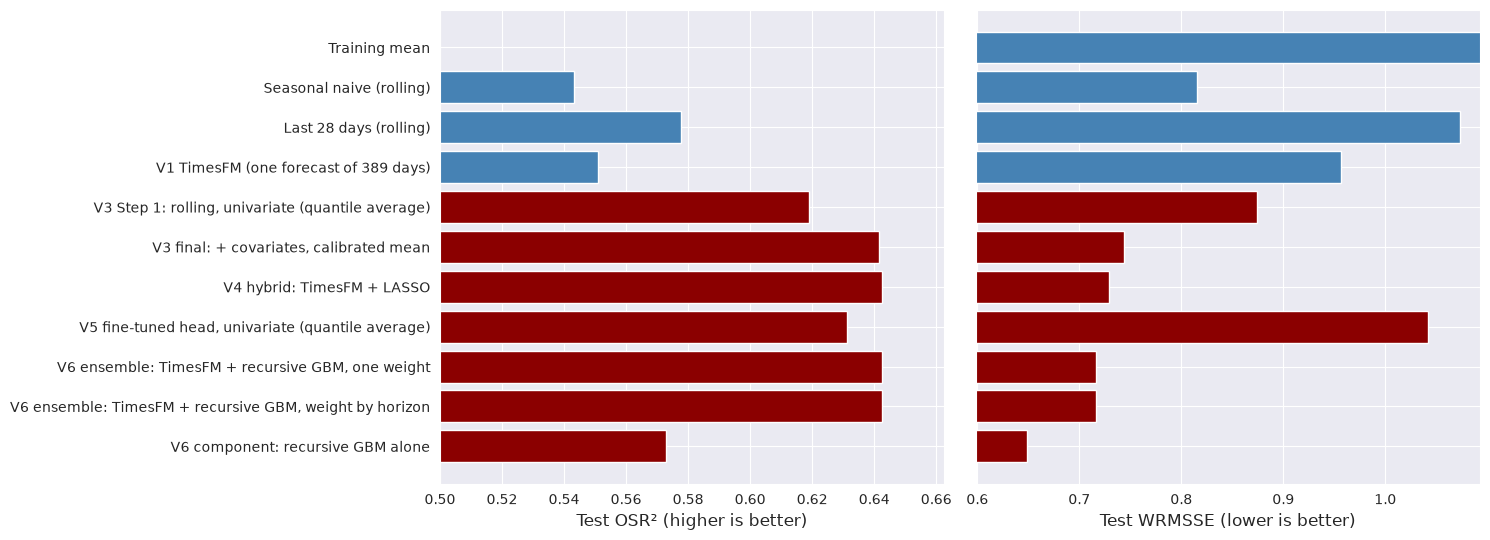

In [45]:
plot_df = comparison.reset_index()
colors = ['steelblue' if v == 'Reference' else 'darkred' for v in plot_df['Version']]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
axes[0].barh(plot_df['Model'], plot_df['OSR²'], color=colors)
axes[0].set_xlim(0.5, plot_df['OSR²'].max() + 0.02)
axes[0].set_xlabel('Test OSR² (higher is better)', fontsize=12)
axes[1].barh(plot_df['Model'], plot_df['WRMSSE'], color=colors)
axes[1].set_xlim(plot_df.loc[plot_df['Version'] != 'Reference', 'WRMSSE'].min() - 0.05,
                 plot_df.loc[plot_df['Model'] != 'Training mean', 'WRMSSE'].max() + 0.02)
axes[1].set_xlabel('Test WRMSSE (lower is better)', fontsize=12)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

### WRMSSE by Level of Aggregation

Each column is the dollar-weighted RMSSE of one of the 12 levels (the WRMSSE is their average). Levels 1–9 are store, state, category and department totals; levels 10–12 are items.

In [46]:
level_table = pd.DataFrame({name: wrmsse(pred, by_level=True) for group, name, pred in final_models
                            if group != 'Reference' or name == 'Seasonal naive (rolling)'}).T
level_table['WRMSSE'] = level_table.mean(axis=1)
display(level_table.round(3).style.format('{:.3f}').background_gradient(cmap='RdYlGn_r', axis=0))

,Total,State,Store,Category,Department,State x category,State x department,Store x category,Store x department,Item,Item x state,Item x store,WRMSSE
Seasonal naive (rolling),0.687,0.714,0.753,0.723,0.783,0.754,0.803,0.798,0.843,0.960,0.944,1.021,0.815
"V3 Step 1: rolling, univariate (quantile average)",0.843,0.827,0.834,0.878,0.914,0.855,0.882,0.852,0.875,0.888,0.859,0.981,0.874
"V3 final: + covariates, calibrated mean",0.632,0.644,0.680,0.678,0.731,0.687,0.735,0.725,0.769,0.858,0.843,0.943,0.744
V4 hybrid: TimesFM + LASSO,0.579,0.605,0.654,0.652,0.709,0.678,0.729,0.723,0.768,0.862,0.846,0.943,0.729
"V5 fine-tuned head, univariate (quantile average)",1.124,1.072,1.057,1.148,1.171,1.083,1.091,1.038,1.030,0.905,0.863,0.922,1.042
"V6 ensemble: TimesFM + recursive GBM, one weight",0.592,0.609,0.650,0.639,0.689,0.654,0.701,0.699,0.743,0.852,0.839,0.934,0.717
"V6 ensemble: TimesFM + recursive GBM, weight by horizon",0.591,0.609,0.650,0.638,0.688,0.654,0.700,0.699,0.743,0.852,0.839,0.933,0.716
V6 component: recursive GBM alone,0.409,0.469,0.561,0.501,0.579,0.552,0.630,0.646,0.716,0.893,0.878,0.950,0.649


### Accuracy by Days Ahead

OSR² by range of days ahead, on windows 2–14, for the final model of each version.

Days ahead,1–7,8–14,15–21,22–28
"V3 Step 1: rolling, univariate (quantile average)",0.6659,0.6348,0.6012,0.5748
"V3 final: + covariates, calibrated mean",0.6682,0.6542,0.6318,0.6151
V4 hybrid: TimesFM + LASSO,0.6683,0.6557,0.6332,0.6158
"V5 fine-tuned head, univariate (quantile average)",0.6613,0.6401,0.6152,0.6092
"V6 ensemble: TimesFM + recursive GBM, one weight",0.6694,0.6557,0.6335,0.6147
"V6 ensemble: TimesFM + recursive GBM, weight by horizon",0.6693,0.6558,0.6330,0.6153
V6 component: recursive GBM alone,0.6230,0.6015,0.5651,0.5071


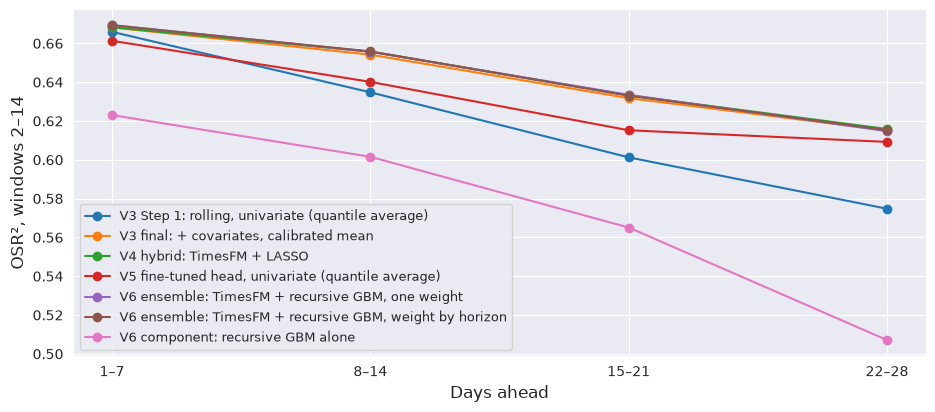

In [47]:
compare_finals = [(name, pred) for group, name, pred in final_models if group != 'Reference']
rows = []
for lo, hi in [(1, 7), (8, 14), (15, 21), (22, 28)]:
    m = later & ((day_ahead >= lo) & (day_ahead <= hi))[None, :]
    rows.append({'Days ahead': f'{lo}–{hi}', **{name: osr2(p[m], y_test[m], y_train_mean)
                                                for name, p in compare_finals}})
by_horizon = pd.DataFrame(rows).set_index('Days ahead')
display(by_horizon.T.round(4))

fig, ax = plt.subplots(figsize=(11, 4.5))
for name, _ in compare_finals:
    ax.plot(by_horizon.index, by_horizon[name], marker='o', label=name)
ax.set_xlabel('Days ahead', fontsize=12)
ax.set_ylabel('OSR², windows 2–14', fontsize=12)
ax.legend(fontsize=9)
plt.show()

### Summary of the Comparison

| Version | What it tests | OSR² | WRMSSE | WAPE | Change vs V3 final | Verdict |
|---|---|---|---|---|---|---|
| **V3** (baseline) | Rolling TimesFM + covariates + calibrated mean | 0.6415 | 0.744 | 75.5% | — | Large gain over V1 (OSR² +0.091, WRMSSE −22%) |
| **V4** (Scenario A) | TimesFM forecast as a LASSO feature | 0.6424 | 0.729 | 75.5% | OSR² +0.001, WRMSSE −2.0% | Small gain, in the totals |
| **V5** (Scenario B) | Fine-tuned output head (univariate) | 0.6313 | 1.042 | 72.8% | vs its baseline V3 Step 1: OSR² +0.012, WRMSSE +19% | Item-level gain, totals far too low |
| **V6** (Scenario C) | Ensemble with recursive gradient-boosted trees | **0.6425** | **0.716** | 75.2% | OSR² +0.001, WRMSSE −3.7% | **Best overall** |

**1. All four versions are within about 0.01 OSR² of each other.** After V3, the three scenarios move OSR² by −0.010 to +0.001. Almost all of the improvement over the starting point came from V3's **rolling re-forecasting** and **stock-out cleaning** (0.551 → 0.631), which give the model fresher and cleaner sales.

**2. V6 is the best model, and it improves every metric.** It is best on OSR², RMSE and WRMSSE, slightly better than V3 on MAE and WAPE, and its total-sales bias is only −0.7%. Its gain is small for item-level accuracy (+0.001 OSR²) but clear for the hierarchy (−3.7% WRMSSE), because the pooled tree model gets the store, state and department totals right more often than TimesFM. V4 helps in the same way, less.

**3. OSR² and WRMSSE can disagree, and the main reason is bias in totals.** V5 improves OSR² but worsens WRMSSE by 19%; the recursive GBM alone has the worst OSR² of the V3–V6 models but the best WRMSSE. A bias of a few percent is invisible for one item on one day but adds up across the thousands of items in a store or state total. The models with the smallest total bias (V3, V4 and V6, all within 1%) have the best WRMSSE among the TimesFM-based models, and V5's −13.5% bias gives it the worst.

**4. MAE and WAPE favor lower, median-like forecasts.** V5, which forecasts lowest, has the best MAE (0.953) and WAPE (72.8%) of the four versions, and the plain TimesFM median does better still (WAPE 68.5%) while being 24% too low in total. With many slow sellers, the median of most series-days is 0, so the absolute-error measures reward forecasts close to 0. They should be read together with the total-sales bias.

**5. Each model is strong at a different level of the hierarchy.** TimesFM (V3, V4) is best for **individual items** (levels 10–12); the pooled recursive GBM is best for **totals** (levels 1–9). This is where the V6 ensemble gains, and it points to an approach used by the top M5 teams: forecast different levels with different models and **reconcile** them.

**6. Accuracy falls with the horizon in every version.** OSR² drops from about 0.67 at 1–7 days ahead to about 0.615 at 22–28 days ahead for every TimesFM-based model. This loss of about 0.05 is far larger than any difference between the versions.

**7. Practical choice.** For a retailer that wants accurate item forecasts and accurate totals, **V6** is the model to use. If simplicity matters, **V3 final** gives nearly the same accuracy with a single model. V5 is not usable without a bias correction.

# Part 4: What Limits Further Improvement

Three quite different additions to V3 (a cross-series regression, fine-tuning and a tree-model ensemble) each moved OSR² by at most about 0.01, and the two that kept the totals right by about 0.001. The diagnostics below look for the reasons.

1. **How similar are the errors of the four versions?** If all models miss the same days, no combination of them can do much better.
2. **How much error is unavoidable?** Daily sales of a single item in a single store are small counts. Even a forecast that knew each day's *expected* sales exactly would still miss the random day-to-day variation around it. For counts, a natural lower bound for this noise is the Poisson variance, which equals the mean.
3. **Where is the remaining error?** We split the squared error of the best model by type of day: days inside a run of zero sales (most likely stock-outs), event days, and other days.
4. **How does the error depend on fresh information?** Accuracy at 1–7 days ahead versus 22–28 days ahead shows the value of more recent sales.

In [48]:
# 1. Correlation of the forecast errors of the four versions (test observations)
errors = pd.DataFrame({name.split(':')[0].split(',')[0]: (pred - y_test)[test_mask]
                       for name, pred in [('V3 final', pred_v3), ('V4 hybrid', pred_hybrid),
                                          ('V5 fine-tuned', q_ft.mean(axis=2)), ('V6 ensemble', pred_ens)]})
print("Correlation of the forecast errors")
display(errors.corr().round(3))

# 2. Unavoidable (Poisson) noise: with a perfect forecast of the expected sales, the expected squared
#    error of each observation is its variance, at least its mean for counts. We estimate the
#    expected sales by the actual sales (their average over the test period equals the mean).
sst = np.sum((y_test_obs - y_train_mean)**2)
best_pred = pred_ens
mse_best = np.mean((best_pred[test_mask] - y_test_obs)**2)
mse_poisson = np.mean(y_test_obs)
print(f"\nMSE of the best model (V6 ensemble):        {mse_best:.3f}")
print(f"Poisson noise alone (mean of daily sales):  {mse_poisson:.3f}  "
      f"({mse_poisson / mse_best:.0%} of the best model's MSE)")
print(f"OSR² ceiling if only Poisson noise remained: {1 - mse_poisson * len(y_test_obs) / sst:.3f} "
      f"(best model: {1 - mse_best * len(y_test_obs) / sst:.3f})")

# Same comparison by sales level: for slow sellers the noise is a larger share of the error
# Series with no training history count as the slowest sellers (training mean 0)
level = pd.qcut(np.broadcast_to(np.nan_to_num(series_mean)[:, None], y_test.shape)[test_mask], 4,
                labels=['Slowest 25%', '25–50%', '50–75%', 'Fastest 25%'])
err2 = (best_pred[test_mask] - y_test_obs)**2
by_level = pd.DataFrame({'sq_err': err2, 'y': y_test_obs, 'level': level}).groupby('level', observed=True)
display(pd.DataFrame({'Average daily sales': by_level['y'].mean(),
                      'MSE of best model': by_level['sq_err'].mean(),
                      'Poisson noise share of MSE': by_level['y'].mean() / by_level['sq_err'].mean()})
        .round(3).style.format({'Poisson noise share of MSE': '{:.0%}'}, precision=3))

Correlation of the forecast errors


,V3 final,V4 hybrid,V5 fine-tuned,V6 ensemble
V3 final,1.000,0.992,0.964,0.998
V4 hybrid,0.992,1.000,0.968,0.991
V5 fine-tuned,0.964,0.968,1.000,0.964
V6 ensemble,0.998,0.991,0.964,1.000



MSE of the best model (V6 ensemble):        4.711
Poisson noise alone (mean of daily sales):  1.309  (28% of the best model's MSE)
OSR² ceiling if only Poisson noise remained: 0.901 (best model: 0.643)


,Average daily sales,MSE of best model,Poisson noise share of MSE
level,,,
Slowest 25%,0.246,0.429,57%
25–50%,0.449,0.699,64%
50–75%,0.923,1.671,55%
Fastest 25%,3.618,16.048,22%


In [49]:
# 3. Where the remaining squared error is: zero-sale runs, event days, other days
zero_run = np.zeros_like(test_mask)
for i in range(n_series):
    for s, e in zip(*zero_runs(units[i, n_train_days:], min_run[i])):
        zero_run[i, s:e] = True
event_day = pd.notna(cal['event_name_1'].to_numpy()[n_train_days:])
day_type = np.where(zero_run, 'Inside a zero-sale run (likely stock-out)',
                    np.where(event_day[None, :], 'Event day', 'Other day'))[test_mask]
sq = (best_pred - y_test)[test_mask]**2
breakdown = pd.DataFrame({'type': day_type, 'sq': sq, 'pred': best_pred[test_mask], 'y': y_test_obs}) \
    .groupby('type').agg(obs=('sq', 'size'), sse=('sq', 'sum'), forecast=('pred', 'mean'), actual=('y', 'mean'))
breakdown['Share of observations'] = breakdown['obs'] / breakdown['obs'].sum()
breakdown['Share of squared error'] = breakdown['sse'] / breakdown['sse'].sum()
display(breakdown[['Share of observations', 'Share of squared error', 'forecast', 'actual']]
        .rename(columns={'forecast': 'Average forecast', 'actual': 'Average actual'})
        .style.format({'Share of observations': '{:.1%}', 'Share of squared error': '{:.1%}',
                       'Average forecast': '{:.2f}', 'Average actual': '{:.2f}'}))

# 4. Value of fresh information: OSR² at 1-7 versus 22-28 days ahead (windows 2-14)
print("OSR² by days ahead, windows 2–14:")
display(by_horizon[[n for n, _ in compare_finals if n.startswith(('V3 final', 'V6 ensemble: TimesFM + recursive GBM, weight'))]]
        .round(4))

,Share of observations,Share of squared error,Average forecast,Average actual
type,,,,
Event day,7.2%,8.1%,1.41,1.43
Inside a zero-sale run (likely stock-out),12.6%,6.7%,0.52,0.00
Other day,80.2%,85.1%,1.41,1.50


OSR² by days ahead, windows 2–14:


,"V3 final: + covariates, calibrated mean","V6 ensemble: TimesFM + recursive GBM, weight by horizon"
Days ahead,,
1–7,0.6682,0.6693
8–14,0.6542,0.6558
15–21,0.6318,0.6330
22–28,0.6151,0.6153


### What Limits the Accuracy

The diagnostics above point to five limits. The first three are properties of the **data and the task**, which no model can remove; the last two are limits of **our setup**, which could still be relaxed.

**1. Most of the remaining error is shared by every model: it is not a modeling problem.** The errors of V3, V4, V5 and V6 are correlated at **0.96 to 0.998**. Four quite different approaches (a pretrained transformer, a linear stacking model, a fine-tuned head and a pooled tree model) miss the same days by about the same amounts. Even the ensemble with weights chosen on the test set itself, which is not a valid forecast, only reaches OSR² 0.643. What is left is variation that the data do not explain.

**2. Daily item sales are noisy, and much of that noise is unpredictable.** Even a perfect forecast of each day's *expected* sales would still miss the random variation of small counts. The Poisson variance alone, the minimum noise of count data, accounts for **28% of the best model's squared error** overall, and for **55% to 64% for the three slower quarters of the series**, where forecasts are already close to the floor. On all 30,490 series, most series-days sell 0 or 1 unit, so this floor matters much more than for the regular sellers (23% there). Real sales vary **more** than Poisson: shoppers buy in multiples, stores receive bulk orders, and local events, weather and competitor promotions shift demand from day to day. None of these drivers is in the M5 data. The Poisson figure (an OSR² ceiling of 0.90) is therefore a loose upper bound; the true ceiling with this information is much closer to what the models reach.

**3. Stock-outs are invisible.** The data record **sales, not demand**, and contain no inventory. The days inside long zero-sale runs, most likely stock-outs, are **12.6% of the test observations** and **6.7% of the squared error**: on these days the best model forecasts 0.52 units on average, while 0 are sold. No model can foresee a stock-out without inventory data.

**4. The forecast horizon: information gets old.** Every version loses about **0.05 OSR²** between 1–7 days and 22–28 days ahead (V6: 0.669 → 0.615). This is the largest single effect we measured, larger than any difference between models. Within the 28-day task, **re-forecasting weekly** with the latest sales, when the business process allows it, would bring every forecast closer to the 1–7-day accuracy.

**5. Limits of our setup that could still be relaxed.**
- **Little data to learn the combinations.** The stacking (V4), the calibrated mean (V3) and the ensemble weights (V6) are learned on the test windows already observed, from 28 to 336 days. Producing rolling TimesFM forecasts over the **training period** would give them several years of examples.
- **Optimized for the wrong metric.** All weights minimize item-level squared error. Optimizing for WRMSSE, or forecasting the totals separately and **reconciling** them with the item forecasts, would use the strength of the pooled tree model at the aggregate levels (Total-level RMSSE 0.41 against 0.63 for TimesFM).
- **Model capacity and bias control.** The M5 winner averaged many LightGBM models (by store, category and department), trained with a Tweedie loss. Our single scikit-learn tree model per forecast date and our head-only fine-tuning use far less capacity, and the fine-tuned head (V5) needs a correction of its total bias before it can be used.

**In short.** With forecasts made up to 28 days ahead from sales, prices and the calendar only, the models are close to what the M5 data can predict for individual items, and the slow sellers make the unavoidable noise larger than for the regular sellers. Further gains are more likely to come from **new information** (more frequent re-forecasting, inventory and stock-out data, local events and weather) and from **better use of the hierarchy** (WRMSSE-oriented weights and reconciliation) than from more complex models built on the same inputs.